In [19]:
import os
import re
import sys

sys.path.append("../")

import analysis
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.signal import periodogram

base_path = r"C:\Users\sl57562\The University of Texas at Austin\Acoustic + Calcium - Documents\Acoustic\pof_mask_comparison_20260821\20260821\20260821"


In [51]:
def analysis_periodogram(power_mw, mask_size, base_path, band_half_width_hz=1e3):
    power_pattern = f"{power_mw}mW_{mask_size}Mask"
    noise_folder = f"{power_pattern}_noise"

    voltage_scans = [
        (float(re.search(r"_(\d+(?:\.\d+)?)V$", folder).group(1)), folder)
        for folder in os.listdir(base_path)
        if os.path.isdir(os.path.join(base_path, folder))
        and folder.startswith(f"{power_pattern}_")
        and "noise" not in folder
        and re.search(r"_(\d+(?:\.\d+)?)V$", folder)
    ]
    voltage_scans.sort(key=lambda item: item[0], reverse=True)
    voltage_folders = [folder for _, folder in voltage_scans]

    if not voltage_scans:
        raise ValueError(f"No voltage scan folders found for {power_pattern}")

    print(f"Analyzing {power_pattern}: found {len(voltage_scans)} voltage scans")

    rows, cols = 4, 3
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows), squeeze=False)
    axes = axes.flatten()

    results = {}

    for ax, (voltage_value, voltage_folder) in zip(axes, voltage_scans):
        frequency_match = re.search(r"_(\d+(?:\.\d+)?)kHz_", voltage_folder)
        if frequency_match is None:
                    center_frequency_hz = 109e3
        else:
            center_frequency_hz = float(frequency_match.group(1)) * 1e3 
            
        signal_path = os.path.join(base_path, voltage_folder)
        noise_path = os.path.join(base_path, noise_folder)

        signal_files = [
            os.path.join(signal_path, f"iter_{x}.tdms")
            for x in range(5) #drop to 5 to exclude data thats further drifted from alignement
            if os.path.exists(os.path.join(signal_path, f"iter_{x}.tdms"))
        ]
        noise_files = [
            os.path.join(noise_path, f"iter_{x}.tdms")
            for x in range(5) #drop to 5 to exclude data thats further drifted from alignement
            if os.path.exists(os.path.join(noise_path, f"iter_{x}.tdms"))
        ]

        if not signal_files or not noise_files:
            print(f"Skipping {voltage_folder}: missing signal or noise files")
            continue

        print(f"  Processing {voltage_folder} with {len(signal_files)} signal files and {len(noise_files)} noise files")

        system = analysis.System(
            f"{power_pattern}_{voltage_folder}",
            signal_files + noise_files,
            channel="X",
            set_data=True,
        )

        freqs = None
        signal_psds = []
        noise_psds = []

        for dataset_idx, dataset in enumerate(system.get_data()):
            dataset.apply("detrend", mode="linear", inplace=True)

            group = "signal" if dataset_idx < len(signal_files) else "noise"

            for collection in dataset.collection:
                sample_rate = getattr(dataset, "r", None)
                if freqs is None:
                    #freqs, psd = welch(collection.x, sample_rate, nfft=2**15, nperseg=2**14)
                    freqs, psd = periodogram(collection.x, sample_rate, nfft=2**15)
                else:
                    #_, psd = welch(collection.x, sample_rate, nfft=2**15, nperseg=2**14)
                    _, psd = periodogram(collection.x, sample_rate, nfft=2**15)

                if group == "signal":
                    signal_psds.append(psd)
                else:
                    noise_psds.append(psd)

        avg_freqs = freqs
        avg_signal_psd = np.mean(np.asarray(signal_psds), axis=0)
        avg_noise_psd = np.mean(np.asarray(noise_psds), axis=0)

        band_min_idx = np.searchsorted(avg_freqs, center_frequency_hz - band_half_width_hz)
        band_max_idx = np.searchsorted(avg_freqs, center_frequency_hz + band_half_width_hz)
        # print(
        #     f"    In-band bounds (Hz): {avg_freqs[band_min_idx]:.0f} to {avg_freqs[max(band_max_idx - 1, band_min_idx)]:.0f}"
        # )

        wideband_signal_power = np.trapezoid(avg_signal_psd, avg_freqs)
        wideband_noise_power = np.trapezoid(avg_noise_psd, avg_freqs)
        snr_wideband = 20 * np.log10(wideband_signal_power / wideband_noise_power)

        # #SNR by integration under curve
        inband_signal_power = np.trapezoid(
            avg_signal_psd[band_min_idx:band_max_idx],
            avg_freqs[band_min_idx:band_max_idx],
        )
        inband_noise_power = np.trapezoid(
            avg_noise_psd[band_min_idx:band_max_idx],
            avg_freqs[band_min_idx:band_max_idx],
        )
        snr_inband = 20 * np.log10(inband_signal_power / inband_noise_power)

        #SNR by maximum
        #how wide of a range it scans is determined by the band_half_width_hz variable in def
        # band_slice = avg_signal_psd[band_min_idx:band_max_idx]
        # local_inband_index = np.argmax(band_slice)
        # inband_signal_index = band_min_idx + local_inband_index
        # # print(inband_signal_index)
        # inband_signal = avg_signal_psd[inband_signal_index]
        # print("Signal value:")
        # print(inband_signal)
        # inband_noise = avg_noise_psd[inband_signal_index]
        # #print(inband_noise)
        # snr_inband = 20 * np.log10(inband_signal / inband_noise)


        results[voltage_value] = {
            "freqs": avg_freqs,
            "signal": avg_signal_psd,
            "noise": avg_noise_psd,
            "snr_wideband": snr_wideband,
            "snr_inband": snr_inband,
            "band_min_idx": band_min_idx,
            "band_max_idx": band_max_idx,
        }
        def calculate_NEP(snr_inband, voltage_value):
            stroke_distance = [0.05, 0.09, 0.14, 0.19, 0.24, 0.30, 0.35, 0.40, 0.46, 0.44] #stroke distance in nm
            rho = 1.2041 #kg/m^3 at 21 degrees C, desnity of air
            c = 343.21 #m/2 @ 21 degrees C, speed of sound in air
            f = center_frequency_hz
            omega = 2*np.pi*f
            X_o = stroke_distance[int(voltage_value-1)] * 1e-9
            P = rho*c*omega*X_o
            if snr_inband < 1.0:
                NEP = "Null"
            else:
                NEP = P / snr_inband 
                NEP = round(NEP, 4)
            return NEP


        ax.loglog(avg_freqs, avg_signal_psd, label="Signal", alpha=0.7)
        ax.loglog(avg_freqs, avg_noise_psd, label="Noise", alpha=0.7)
        # ax.axvline(avg_freqs[band_min_idx], color="k", linestyle="--", linewidth=0.5)
        # ax.axvline(avg_freqs[max(band_max_idx - 1, band_min_idx)], color="k", linestyle="--", linewidth=0.5)
        ax.set_title(f"{voltage_value} V\nIn-band SNR: {snr_inband:.1f} dB\nNEP: {calculate_NEP(snr_inband, voltage_value)} Pa")
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=7)
        ax.set_ylim(1e-16, 1e-6)

        print(f"    In-band SNR: {snr_inband:.2f} dB | Wideband SNR: {snr_wideband:.2f} dB")
        print(f"    NEP: {calculate_NEP(snr_inband, voltage_value)} Pa")

    for ax in axes[len(results):]:
        ax.set_visible(False)

    fig.suptitle(f"Mask size: {mask_size} PSDs and SNRs\n")
    fig.tight_layout()
    # plt.show()

# plots snr vs voltage    
    # voltage_values = sorted(results.keys())
    # snr_values = [results[voltage]["snr_inband"] for voltage in voltage_values]

    # fig2, ax2 = plt.subplots(figsize=(6, 4))
    # ax2.plot(voltage_values, snr_values, "o-", color="tab:blue")
    # ax2.set_xlabel("Voltage (V)")
    # ax2.set_ylabel("In-band SNR (dB)")
    # ax2.set_title(f"{power_mw} mW: SNR vs voltage")
    # ax2.grid(True, alpha=0.3)
    # fig2.tight_layout()
    # plt.show()

    return results

Analyzing 20mW_noMask: found 10 voltage scans
  Processing 20mW_noMask_10V with 5 signal files and 5 noise files
    In-band SNR: 24.02 dB | Wideband SNR: -0.19 dB
    NEP: 0.0052 Pa
  Processing 20mW_noMask_9V with 5 signal files and 5 noise files
    In-band SNR: 24.71 dB | Wideband SNR: -0.09 dB
    NEP: 0.0053 Pa
  Processing 20mW_noMask_8V with 5 signal files and 5 noise files
    In-band SNR: 13.80 dB | Wideband SNR: -0.28 dB
    NEP: 0.0082 Pa
  Processing 20mW_noMask_7V with 5 signal files and 5 noise files
    In-band SNR: 12.21 dB | Wideband SNR: -0.21 dB
    NEP: 0.0081 Pa
  Processing 20mW_noMask_6V with 5 signal files and 5 noise files
    In-band SNR: 12.87 dB | Wideband SNR: -0.12 dB
    NEP: 0.0066 Pa
  Processing 20mW_noMask_5V with 5 signal files and 5 noise files
    In-band SNR: 15.19 dB | Wideband SNR: -0.19 dB
    NEP: 0.0045 Pa
  Processing 20mW_noMask_4V with 5 signal files and 5 noise files
    In-band SNR: 14.49 dB | Wideband SNR: -0.11 dB
    NEP: 0.0037 Pa
 

Analyzing 20mW_noMask: found 10 voltage scans
  Processing 20mW_noMask_10V with 5 signal files and 5 noise files
    In-band SNR: 24.02 dB | Wideband SNR: -0.19 dB
    NEP: 0.0052 Pa
  Processing 20mW_noMask_9V with 5 signal files and 5 noise files
    In-band SNR: 24.71 dB | Wideband SNR: -0.09 dB
    NEP: 0.0053 Pa
  Processing 20mW_noMask_8V with 5 signal files and 5 noise files
    In-band SNR: 13.80 dB | Wideband SNR: -0.28 dB
    NEP: 0.0082 Pa
  Processing 20mW_noMask_7V with 5 signal files and 5 noise files
    In-band SNR: 12.21 dB | Wideband SNR: -0.21 dB
    NEP: 0.0081 Pa
  Processing 20mW_noMask_6V with 5 signal files and 5 noise files
    In-band SNR: 12.87 dB | Wideband SNR: -0.12 dB
    NEP: 0.0066 Pa
  Processing 20mW_noMask_5V with 5 signal files and 5 noise files
    In-band SNR: 15.19 dB | Wideband SNR: -0.19 dB
    NEP: 0.0045 Pa
  Processing 20mW_noMask_4V with 5 signal files and 5 noise files
    In-band SNR: 14.49 dB | Wideband SNR: -0.11 dB
    NEP: 0.0037 Pa
 

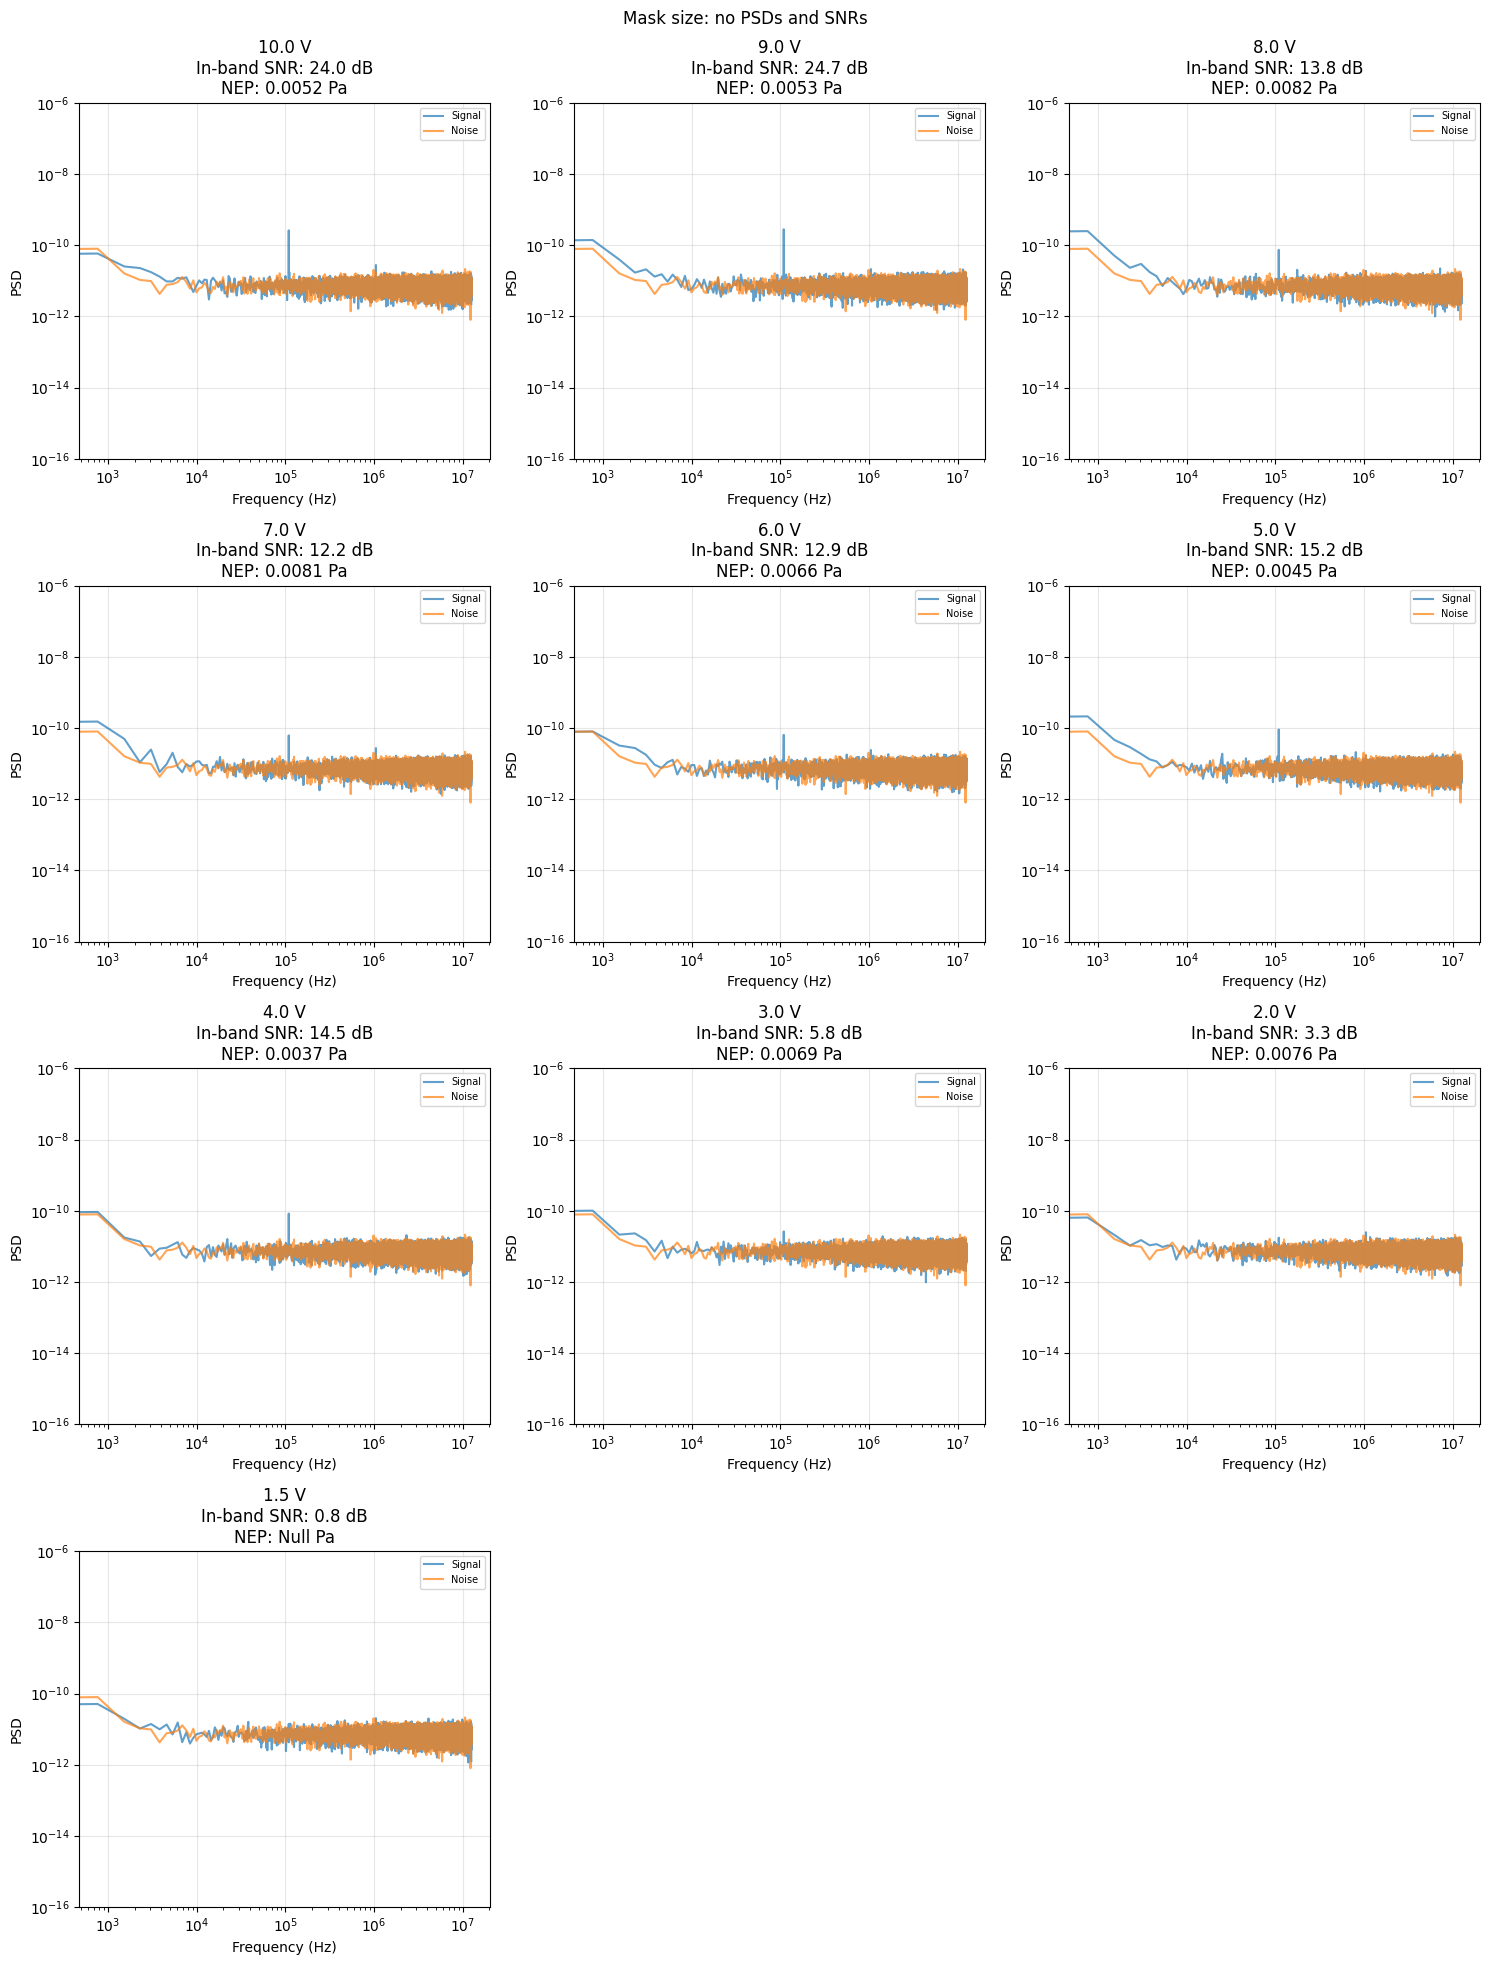

In [41]:
results = analysis_periodogram(20, "no", base_path, band_half_width_hz=1e3)

Analyzing 20mW_0.6mmMask: found 10 voltage scans
  Processing 20mW_0.6mmMask_10V with 5 signal files and 5 noise files
    In-band SNR: 15.16 dB | Wideband SNR: 0.16 dB
    NEP: 0.0082 Pa
  Processing 20mW_0.6mmMask_9V with 5 signal files and 5 noise files
    In-band SNR: 10.34 dB | Wideband SNR: -0.02 dB
    NEP: 0.0126 Pa
  Processing 20mW_0.6mmMask_8V with 5 signal files and 5 noise files
    In-band SNR: 7.76 dB | Wideband SNR: -0.10 dB
    NEP: 0.0146 Pa
  Processing 20mW_0.6mmMask_7V with 5 signal files and 5 noise files
    In-band SNR: 11.26 dB | Wideband SNR: 0.03 dB
    NEP: 0.0088 Pa
  Processing 20mW_0.6mmMask_6V with 5 signal files and 5 noise files
    In-band SNR: 7.65 dB | Wideband SNR: -0.77 dB
    NEP: 0.0111 Pa
  Processing 20mW_0.6mmMask_5V with 5 signal files and 5 noise files
    In-band SNR: 4.12 dB | Wideband SNR: -0.72 dB
    NEP: 0.0165 Pa
  Processing 20mW_0.6mmMask_4V with 5 signal files and 5 noise files
    In-band SNR: 4.97 dB | Wideband SNR: -0.90 dB
  

Analyzing 20mW_0.6mmMask: found 10 voltage scans
  Processing 20mW_0.6mmMask_10V with 5 signal files and 5 noise files
    In-band SNR: 15.16 dB | Wideband SNR: 0.16 dB
    NEP: 0.0082 Pa
  Processing 20mW_0.6mmMask_9V with 5 signal files and 5 noise files
    In-band SNR: 10.34 dB | Wideband SNR: -0.02 dB
    NEP: 0.0126 Pa
  Processing 20mW_0.6mmMask_8V with 5 signal files and 5 noise files
    In-band SNR: 7.76 dB | Wideband SNR: -0.10 dB
    NEP: 0.0146 Pa
  Processing 20mW_0.6mmMask_7V with 5 signal files and 5 noise files
    In-band SNR: 11.26 dB | Wideband SNR: 0.03 dB
    NEP: 0.0088 Pa
  Processing 20mW_0.6mmMask_6V with 5 signal files and 5 noise files
    In-band SNR: 7.65 dB | Wideband SNR: -0.77 dB
    NEP: 0.0111 Pa
  Processing 20mW_0.6mmMask_5V with 5 signal files and 5 noise files
    In-band SNR: 4.12 dB | Wideband SNR: -0.72 dB
    NEP: 0.0165 Pa
  Processing 20mW_0.6mmMask_4V with 5 signal files and 5 noise files
    In-band SNR: 4.97 dB | Wideband SNR: -0.90 dB
  

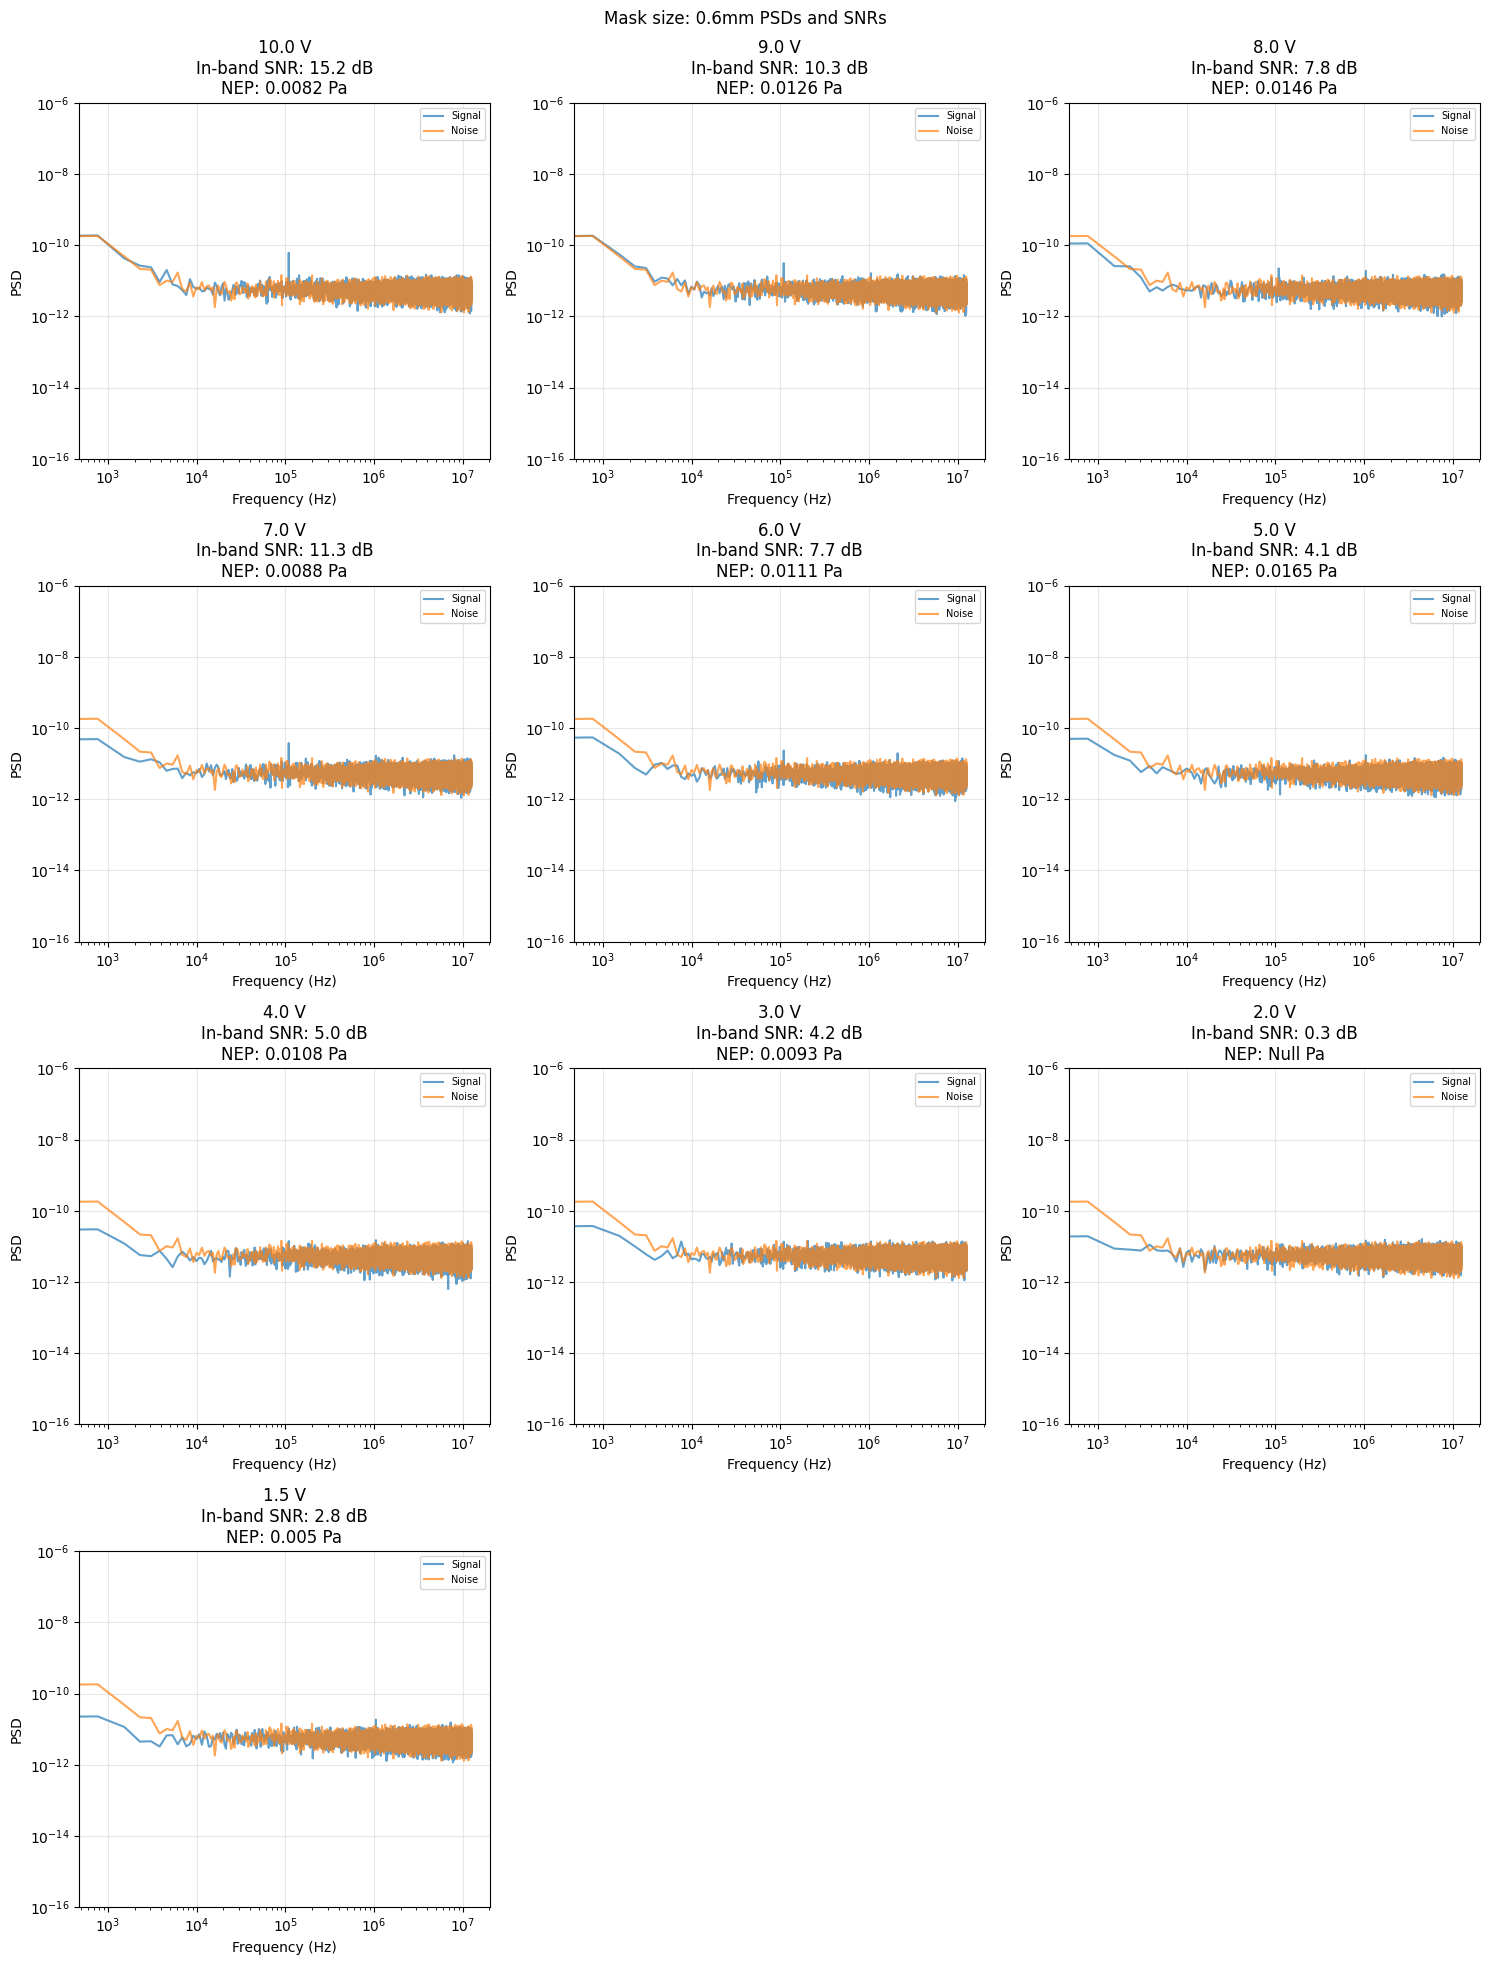

In [42]:
results = analysis_periodogram(20, "0.6mm", base_path, band_half_width_hz=1e3)

Analyzing 20mW_0.8mmMask: found 10 voltage scans
  Processing 20mW_0.8mmMask_10V with 5 signal files and 5 noise files
    In-band SNR: 15.85 dB | Wideband SNR: -0.62 dB
    NEP: 0.0079 Pa
  Processing 20mW_0.8mmMask_9V with 5 signal files and 5 noise files
    In-band SNR: 12.58 dB | Wideband SNR: -0.14 dB
    NEP: 0.0104 Pa
  Processing 20mW_0.8mmMask_8V with 5 signal files and 5 noise files
    In-band SNR: 10.82 dB | Wideband SNR: -0.18 dB
    NEP: 0.0105 Pa
  Processing 20mW_0.8mmMask_7V with 5 signal files and 5 noise files
    In-band SNR: 10.37 dB | Wideband SNR: -0.17 dB
    NEP: 0.0096 Pa
  Processing 20mW_0.8mmMask_6V with 5 signal files and 5 noise files
    In-band SNR: 6.22 dB | Wideband SNR: -0.17 dB
    NEP: 0.0136 Pa
  Processing 20mW_0.8mmMask_5V with 5 signal files and 5 noise files
    In-band SNR: 6.40 dB | Wideband SNR: -0.08 dB
    NEP: 0.0106 Pa
  Processing 20mW_0.8mmMask_4V with 5 signal files and 5 noise files
    In-band SNR: 1.40 dB | Wideband SNR: -0.16 dB

Analyzing 20mW_0.8mmMask: found 10 voltage scans
  Processing 20mW_0.8mmMask_10V with 5 signal files and 5 noise files
    In-band SNR: 15.85 dB | Wideband SNR: -0.62 dB
    NEP: 0.0079 Pa
  Processing 20mW_0.8mmMask_9V with 5 signal files and 5 noise files
    In-band SNR: 12.58 dB | Wideband SNR: -0.14 dB
    NEP: 0.0104 Pa
  Processing 20mW_0.8mmMask_8V with 5 signal files and 5 noise files
    In-band SNR: 10.82 dB | Wideband SNR: -0.18 dB
    NEP: 0.0105 Pa
  Processing 20mW_0.8mmMask_7V with 5 signal files and 5 noise files
    In-band SNR: 10.37 dB | Wideband SNR: -0.17 dB
    NEP: 0.0096 Pa
  Processing 20mW_0.8mmMask_6V with 5 signal files and 5 noise files
    In-band SNR: 6.22 dB | Wideband SNR: -0.17 dB
    NEP: 0.0136 Pa
  Processing 20mW_0.8mmMask_5V with 5 signal files and 5 noise files
    In-band SNR: 6.40 dB | Wideband SNR: -0.08 dB
    NEP: 0.0106 Pa
  Processing 20mW_0.8mmMask_4V with 5 signal files and 5 noise files
    In-band SNR: 1.40 dB | Wideband SNR: -0.16 dB

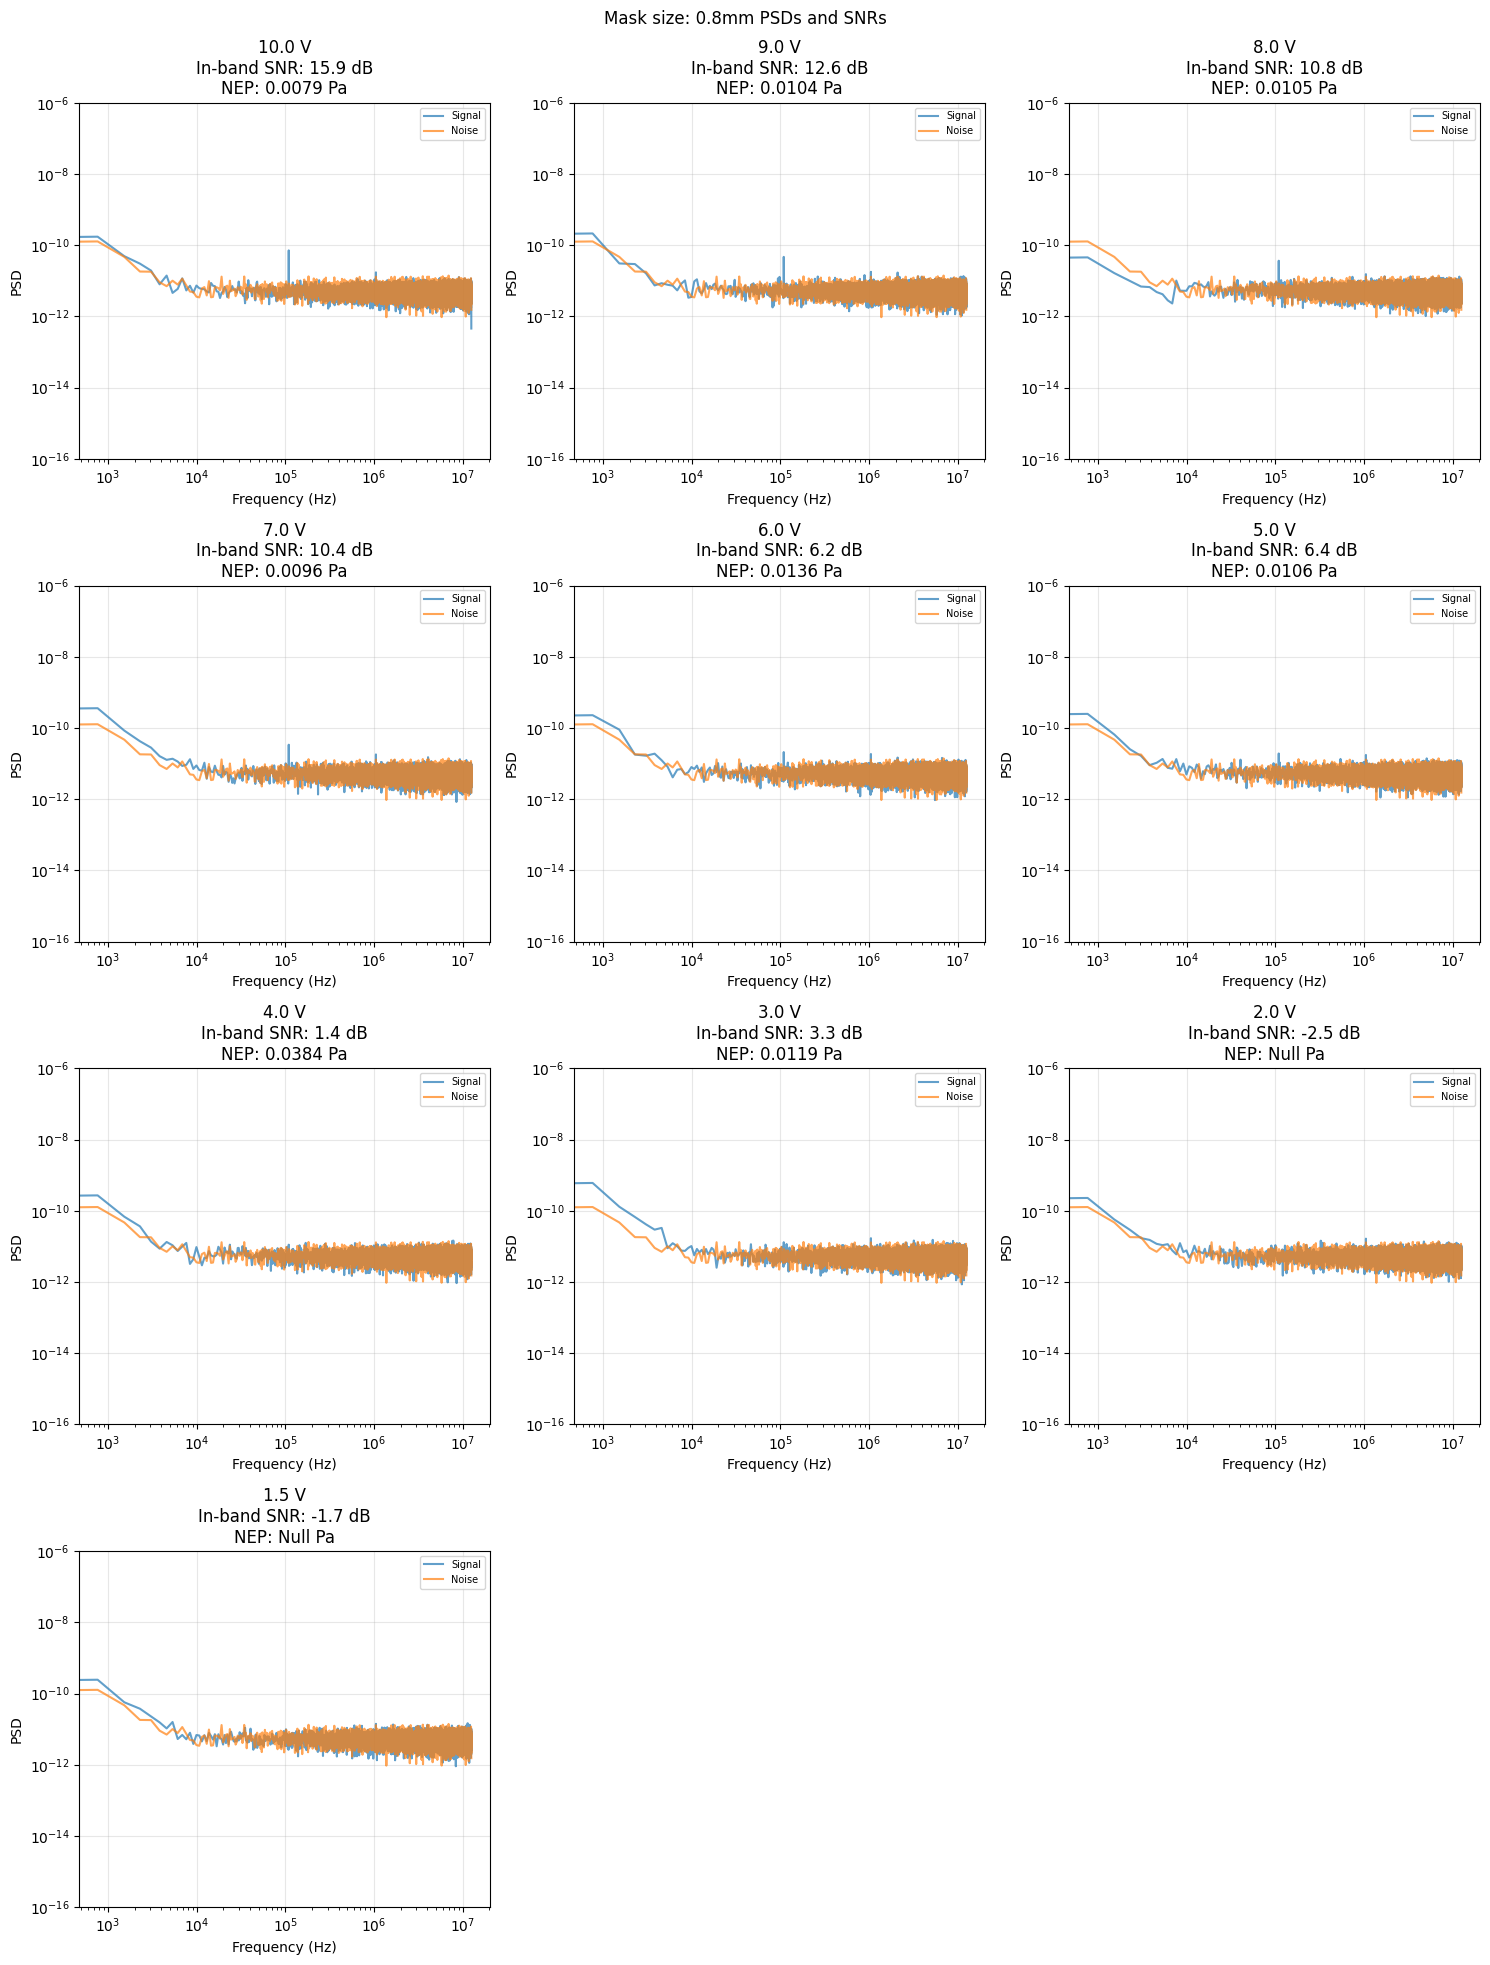

In [43]:
results = analysis_periodogram(20, "0.8mm", base_path, band_half_width_hz=1e3)

Analyzing 20mW_0.94mmMask: found 10 voltage scans
  Processing 20mW_0.94mmMask_10V with 5 signal files and 5 noise files
    In-band SNR: 19.91 dB | Wideband SNR: 0.02 dB
    NEP: 0.0063 Pa
  Processing 20mW_0.94mmMask_9V with 5 signal files and 5 noise files
    In-band SNR: 18.82 dB | Wideband SNR: 0.07 dB
    NEP: 0.0069 Pa
  Processing 20mW_0.94mmMask_8V with 5 signal files and 5 noise files
    In-band SNR: 13.89 dB | Wideband SNR: 0.15 dB
    NEP: 0.0082 Pa
  Processing 20mW_0.94mmMask_7V with 5 signal files and 5 noise files
    In-band SNR: 17.11 dB | Wideband SNR: 0.20 dB
    NEP: 0.0058 Pa
  Processing 20mW_0.94mmMask_6V with 5 signal files and 5 noise files
    In-band SNR: 12.07 dB | Wideband SNR: 0.26 dB
    NEP: 0.007 Pa
  Processing 20mW_0.94mmMask_5V with 5 signal files and 5 noise files
    In-band SNR: 11.72 dB | Wideband SNR: 0.15 dB
    NEP: 0.0058 Pa
  Processing 20mW_0.94mmMask_4V with 5 signal files and 5 noise files
    In-band SNR: 8.33 dB | Wideband SNR: 0.15 

Analyzing 20mW_0.94mmMask: found 10 voltage scans
  Processing 20mW_0.94mmMask_10V with 5 signal files and 5 noise files
    In-band SNR: 19.91 dB | Wideband SNR: 0.02 dB
    NEP: 0.0063 Pa
  Processing 20mW_0.94mmMask_9V with 5 signal files and 5 noise files
    In-band SNR: 18.82 dB | Wideband SNR: 0.07 dB
    NEP: 0.0069 Pa
  Processing 20mW_0.94mmMask_8V with 5 signal files and 5 noise files
    In-band SNR: 13.89 dB | Wideband SNR: 0.15 dB
    NEP: 0.0082 Pa
  Processing 20mW_0.94mmMask_7V with 5 signal files and 5 noise files
    In-band SNR: 17.11 dB | Wideband SNR: 0.20 dB
    NEP: 0.0058 Pa
  Processing 20mW_0.94mmMask_6V with 5 signal files and 5 noise files
    In-band SNR: 12.07 dB | Wideband SNR: 0.26 dB
    NEP: 0.007 Pa
  Processing 20mW_0.94mmMask_5V with 5 signal files and 5 noise files
    In-band SNR: 11.72 dB | Wideband SNR: 0.15 dB
    NEP: 0.0058 Pa
  Processing 20mW_0.94mmMask_4V with 5 signal files and 5 noise files
    In-band SNR: 8.33 dB | Wideband SNR: 0.15 

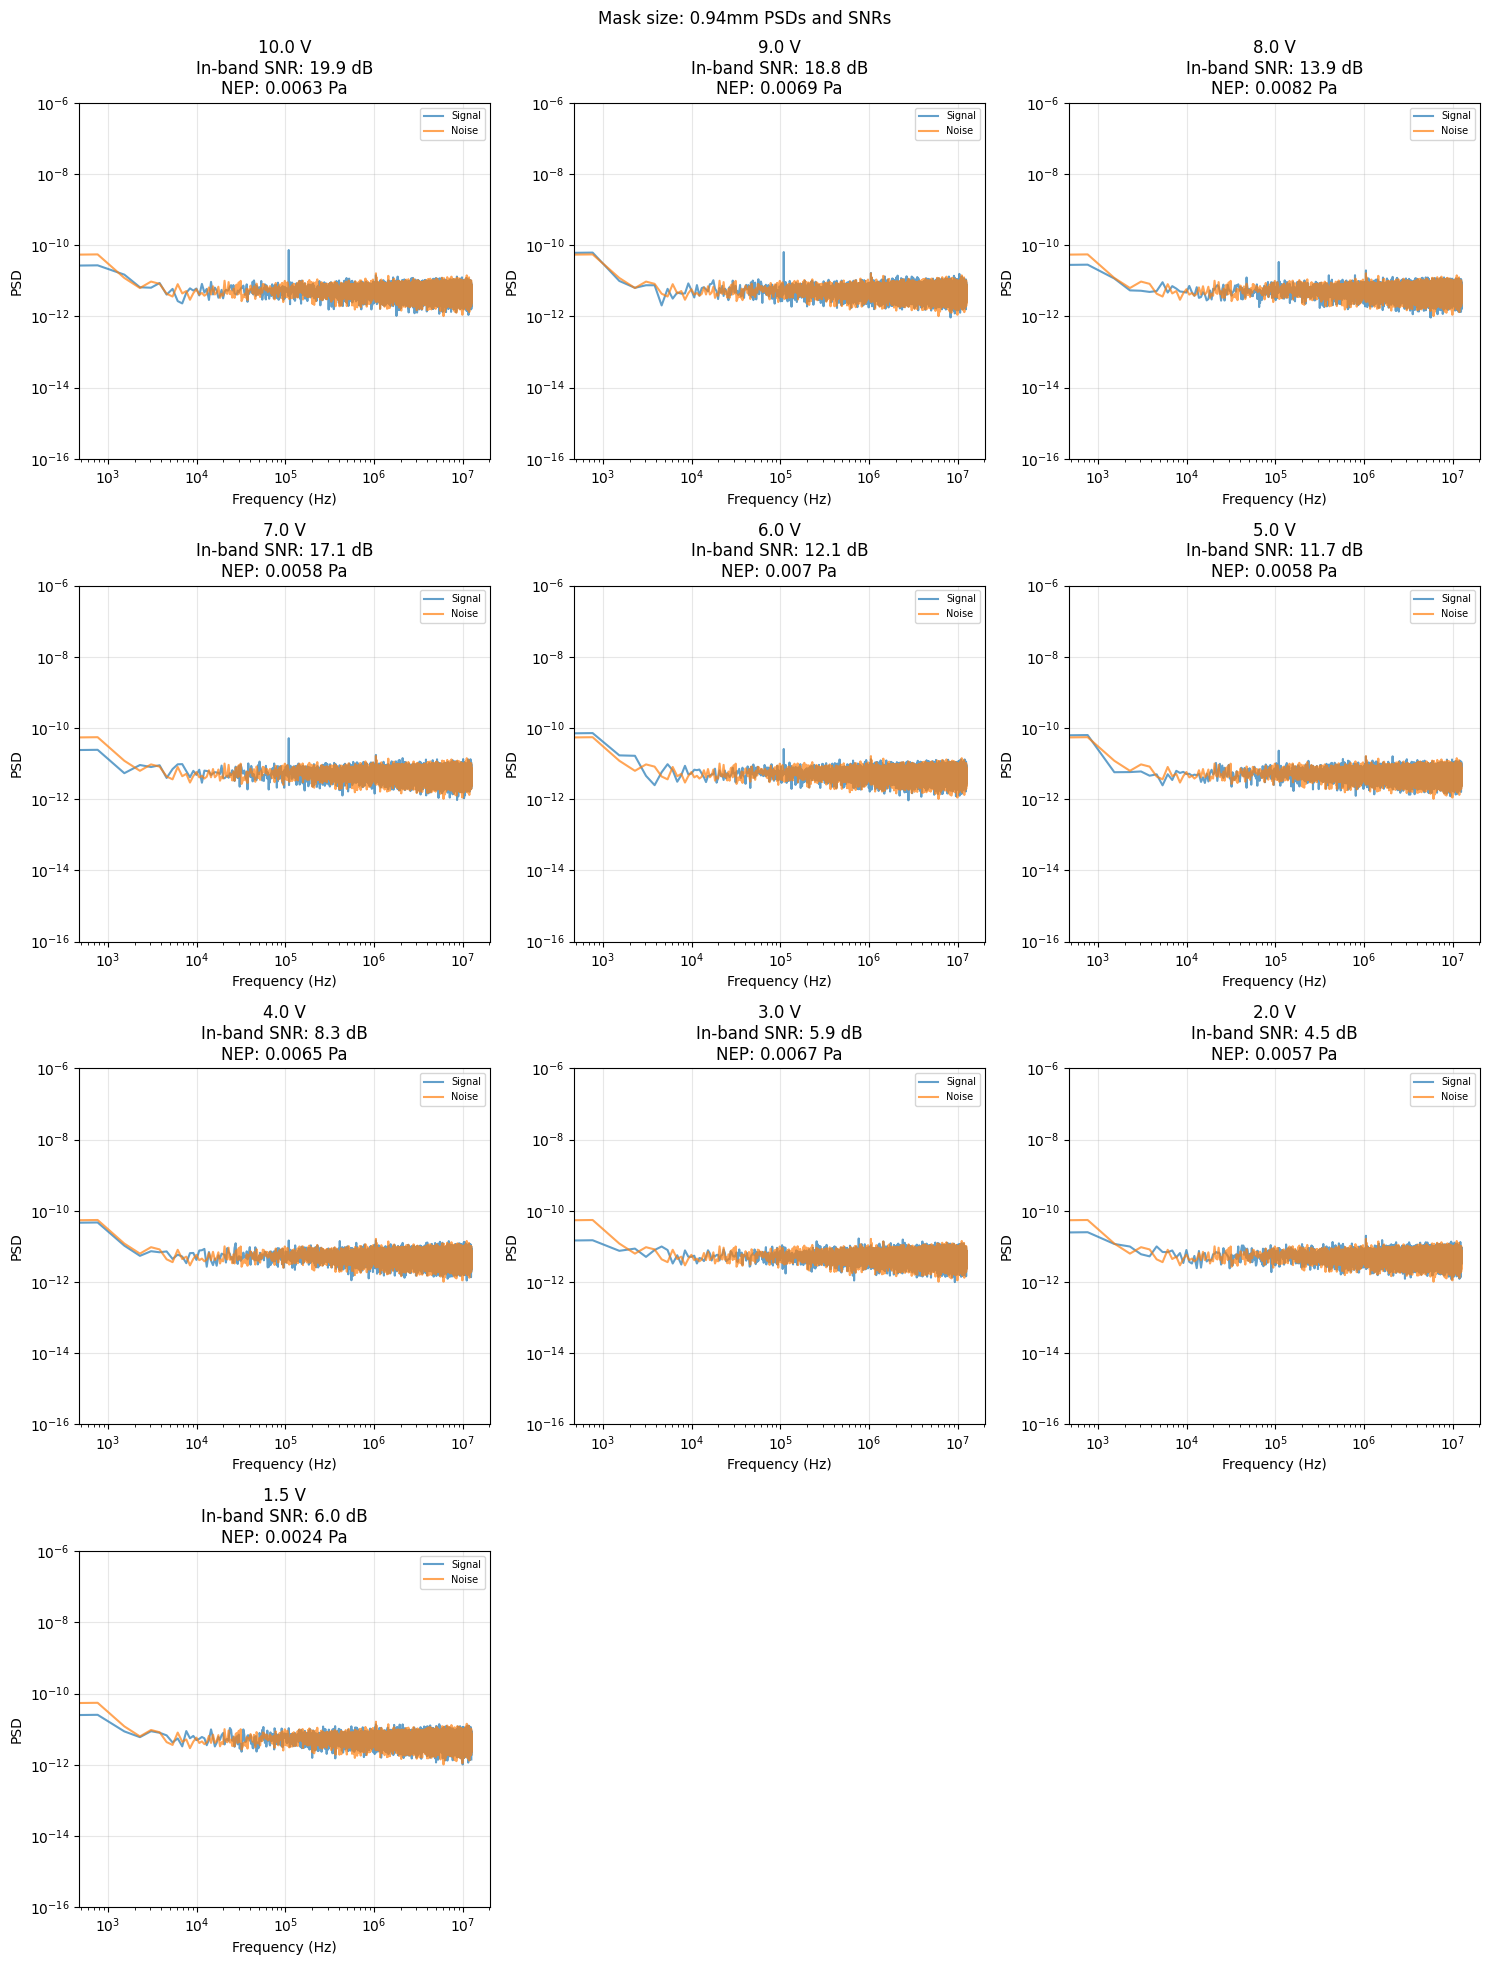

In [44]:
results = analysis_periodogram(20, "0.94mm", base_path, band_half_width_hz=1e3)

In [56]:
def analysis_welches(power_mw, mask_size, base_path, band_half_width_hz=1e3):
    power_pattern = f"{power_mw}mW_{mask_size}Mask"
    noise_folder = f"{power_pattern}_noise"

    voltage_scans = [
        (float(re.search(r"_(\d+(?:\.\d+)?)V$", folder).group(1)), folder)
        for folder in os.listdir(base_path)
        if os.path.isdir(os.path.join(base_path, folder))
        and folder.startswith(f"{power_pattern}_")
        and "noise" not in folder
        and re.search(r"_(\d+(?:\.\d+)?)V$", folder)
    ]
    voltage_scans.sort(key=lambda item: item[0], reverse=True)
    voltage_folders = [folder for _, folder in voltage_scans]

    if not voltage_scans:
        raise ValueError(f"No voltage scan folders found for {power_pattern}")

    print(f"Analyzing {power_pattern}: found {len(voltage_scans)} voltage scans")

    rows, cols = 4, 3
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows), squeeze=False)
    axes = axes.flatten()

    results = {}

    for ax, (voltage_value, voltage_folder) in zip(axes, voltage_scans):
        frequency_match = re.search(r"_(\d+(?:\.\d+)?)kHz_", voltage_folder)
        if frequency_match is None:
            center_frequency_hz = 109e3
        else:
            center_frequency_hz = float(frequency_match.group(1)) * 1e3

        signal_path = os.path.join(base_path, voltage_folder)
        noise_path = os.path.join(base_path, noise_folder)

        signal_files = [
            os.path.join(signal_path, f"iter_{x}.tdms")
            for x in range(5) #drop to 5 to exclude data thats further drifted from alignement
            if os.path.exists(os.path.join(signal_path, f"iter_{x}.tdms"))
        ]
        noise_files = [
            os.path.join(noise_path, f"iter_{x}.tdms")
            for x in range(5) #drop to 5 to exclude data thats further drifted from alignement
            if os.path.exists(os.path.join(noise_path, f"iter_{x}.tdms"))
        ]

        if not signal_files or not noise_files:
            print(f"Skipping {voltage_folder}: missing signal or noise files")
            continue

        print(f"  Processing {voltage_folder} with {len(signal_files)} signal files and {len(noise_files)} noise files")

        system = analysis.System(
            f"{power_pattern}_{voltage_folder}",
            signal_files + noise_files,
            channel="X",
            set_data=True,
        )

        freqs = None
        signal_psds = []
        noise_psds = []

        for dataset_idx, dataset in enumerate(system.get_data()):
            dataset.apply("detrend", mode="linear", inplace=True)

            group = "signal" if dataset_idx < len(signal_files) else "noise"

            for collection in dataset.collection:
                sample_rate = getattr(dataset, "r", None)
                if freqs is None:
                    freqs, psd = welch(collection.x, sample_rate, nfft=2**15, nperseg=2**14)
                else:
                    _, psd = welch(collection.x, sample_rate, nfft=2**15, nperseg=2**14)

                if group == "signal":
                    signal_psds.append(psd)
                else:
                    noise_psds.append(psd)

        avg_freqs = freqs
        avg_signal_psd = np.mean(np.asarray(signal_psds), axis=0)
        avg_noise_psd = np.mean(np.asarray(noise_psds), axis=0)

        band_min_idx = np.searchsorted(avg_freqs, center_frequency_hz - band_half_width_hz)
        band_max_idx = np.searchsorted(avg_freqs, center_frequency_hz + band_half_width_hz)
        # print(
        #     f"    In-band bounds (Hz): {avg_freqs[band_min_idx]:.0f} to {avg_freqs[max(band_max_idx - 1, band_min_idx)]:.0f}"
        # )

        wideband_signal_power = np.trapezoid(avg_signal_psd, avg_freqs)
        wideband_noise_power = np.trapezoid(avg_noise_psd, avg_freqs)
        snr_wideband = 20 * np.log10(wideband_signal_power / wideband_noise_power)

        # SNR by integration

        inband_signal_power = np.trapezoid(
            avg_signal_psd[band_min_idx:band_max_idx],
            avg_freqs[band_min_idx:band_max_idx],
        )
        inband_noise_power = np.trapezoid(
            avg_noise_psd[band_min_idx:band_max_idx],
            avg_freqs[band_min_idx:band_max_idx],
        )
        snr_inband = 20 * np.log10(inband_signal_power / inband_noise_power)

        #SNR by maximum
        # #how wide of a range it scans is determined by the band_half_width_hz variable in def
        # band_slice = avg_signal_psd[band_min_idx:band_max_idx]
        # local_inband_index = np.argmax(band_slice)
        # inband_signal_index = band_min_idx + local_inband_index
        # #print(inband_signal_index)
        # inband_signal = avg_signal_psd[inband_signal_index]
        # #print(inband_signal)
        # inband_noise = avg_noise_psd[inband_signal_index]
        # #print(inband_noise)
        # snr_inband = 20 * np.log10(inband_signal / inband_noise)

        results[voltage_value] = {
            "freqs": avg_freqs,
            "signal": avg_signal_psd,
            "noise": avg_noise_psd,
            "snr_wideband": snr_wideband,
            "snr_inband": snr_inband,
            "band_min_idx": band_min_idx,
            "band_max_idx": band_max_idx,
        }

        def calculate_NEP(snr_inband, voltage_value):
            stroke_distance = [0.05, 0.09, 0.14, 0.19, 0.24, 0.30, 0.35, 0.40, 0.46, 0.44] #stroke distance in nm
            rho = 1.2041 #kg/m^3 at 21 degrees C, desnity of air
            c = 343.21 #m/2 @ 21 degrees C, speed of sound in air
            f = center_frequency_hz
            omega = 2*np.pi*f
            X_o = stroke_distance[int(voltage_value-1)] * 1e-9
            P = rho*c*omega*X_o
            if snr_inband < 1.0:
                NEP = "Null"
            else:
                NEP = P / snr_inband 
                NEP = round(NEP, 4)
            return NEP

        ax.loglog(avg_freqs, avg_signal_psd, label="Signal", alpha=0.7)
        ax.loglog(avg_freqs, avg_noise_psd, label="Noise", alpha=0.7)
        # ax.axvline(avg_freqs[band_min_idx], color="k", linestyle="--", linewidth=0.5)
        # ax.axvline(avg_freqs[max(band_max_idx - 1, band_min_idx)], color="k", linestyle="--", linewidth=0.5)

        ax.set_title(f"{voltage_value} V\nIn-band SNR: {snr_inband:.1f} dB\nNEP: {calculate_NEP(snr_inband, voltage_value)} Pa")
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=7)
        ax.set_ylim(1e-16, 1e-6)

        print(f"    In-band SNR: {snr_inband:.2f} dB")
        print(f"    NEP: {calculate_NEP(snr_inband, voltage_value)} Pa")

    for ax in axes[len(results):]:
        ax.set_visible(False)

    fig.suptitle(f"Mask size: {mask_size} PSDs and SNRs\n")
    fig.tight_layout()
    # plt.show()

# plots snr vs voltage
    # voltage_values = sorted(results.keys())
    # snr_values = [results[voltage]["snr_inband"] for voltage in voltage_values]

    # fig2, ax2 = plt.subplots(figsize=(6, 4))
    # ax2.plot(voltage_values, snr_values, "o-", color="tab:blue")
    # ax2.set_xlabel("Voltage (V)")
    # ax2.set_ylabel("In-band SNR (dB)")
    # ax2.set_title(f"{power_mw} mW: SNR vs voltage")
    # ax2.grid(True, alpha=0.3)
    # fig2.tight_layout()
    # plt.show()

    return results

Analyzing 20mW_noMask: found 10 voltage scans
  Processing 20mW_noMask_10V with 5 signal files and 5 noise files
    In-band SNR: 21.44 dB
    NEP: 0.0058 Pa
  Processing 20mW_noMask_9V with 5 signal files and 5 noise files
    In-band SNR: 21.47 dB
    NEP: 0.0061 Pa
  Processing 20mW_noMask_8V with 5 signal files and 5 noise files
    In-band SNR: 12.93 dB
    NEP: 0.0088 Pa
  Processing 20mW_noMask_7V with 5 signal files and 5 noise files
    In-band SNR: 11.94 dB
    NEP: 0.0083 Pa
  Processing 20mW_noMask_6V with 5 signal files and 5 noise files
    In-band SNR: 12.02 dB
    NEP: 0.0071 Pa
  Processing 20mW_noMask_5V with 5 signal files and 5 noise files
    In-band SNR: 12.98 dB
    NEP: 0.0052 Pa
  Processing 20mW_noMask_4V with 5 signal files and 5 noise files
    In-band SNR: 13.13 dB
    NEP: 0.0041 Pa
  Processing 20mW_noMask_3V with 5 signal files and 5 noise files
    In-band SNR: 5.03 dB
    NEP: 0.0079 Pa
  Processing 20mW_noMask_2V with 5 signal files and 5 noise files


Analyzing 20mW_noMask: found 10 voltage scans
  Processing 20mW_noMask_10V with 5 signal files and 5 noise files
    In-band SNR: 21.44 dB
    NEP: 0.0058 Pa
  Processing 20mW_noMask_9V with 5 signal files and 5 noise files
    In-band SNR: 21.47 dB
    NEP: 0.0061 Pa
  Processing 20mW_noMask_8V with 5 signal files and 5 noise files
    In-band SNR: 12.93 dB
    NEP: 0.0088 Pa
  Processing 20mW_noMask_7V with 5 signal files and 5 noise files
    In-band SNR: 11.94 dB
    NEP: 0.0083 Pa
  Processing 20mW_noMask_6V with 5 signal files and 5 noise files
    In-band SNR: 12.02 dB
    NEP: 0.0071 Pa
  Processing 20mW_noMask_5V with 5 signal files and 5 noise files
    In-band SNR: 12.98 dB
    NEP: 0.0052 Pa
  Processing 20mW_noMask_4V with 5 signal files and 5 noise files
    In-band SNR: 13.13 dB
    NEP: 0.0041 Pa
  Processing 20mW_noMask_3V with 5 signal files and 5 noise files
    In-band SNR: 5.03 dB
    NEP: 0.0079 Pa
  Processing 20mW_noMask_2V with 5 signal files and 5 noise files


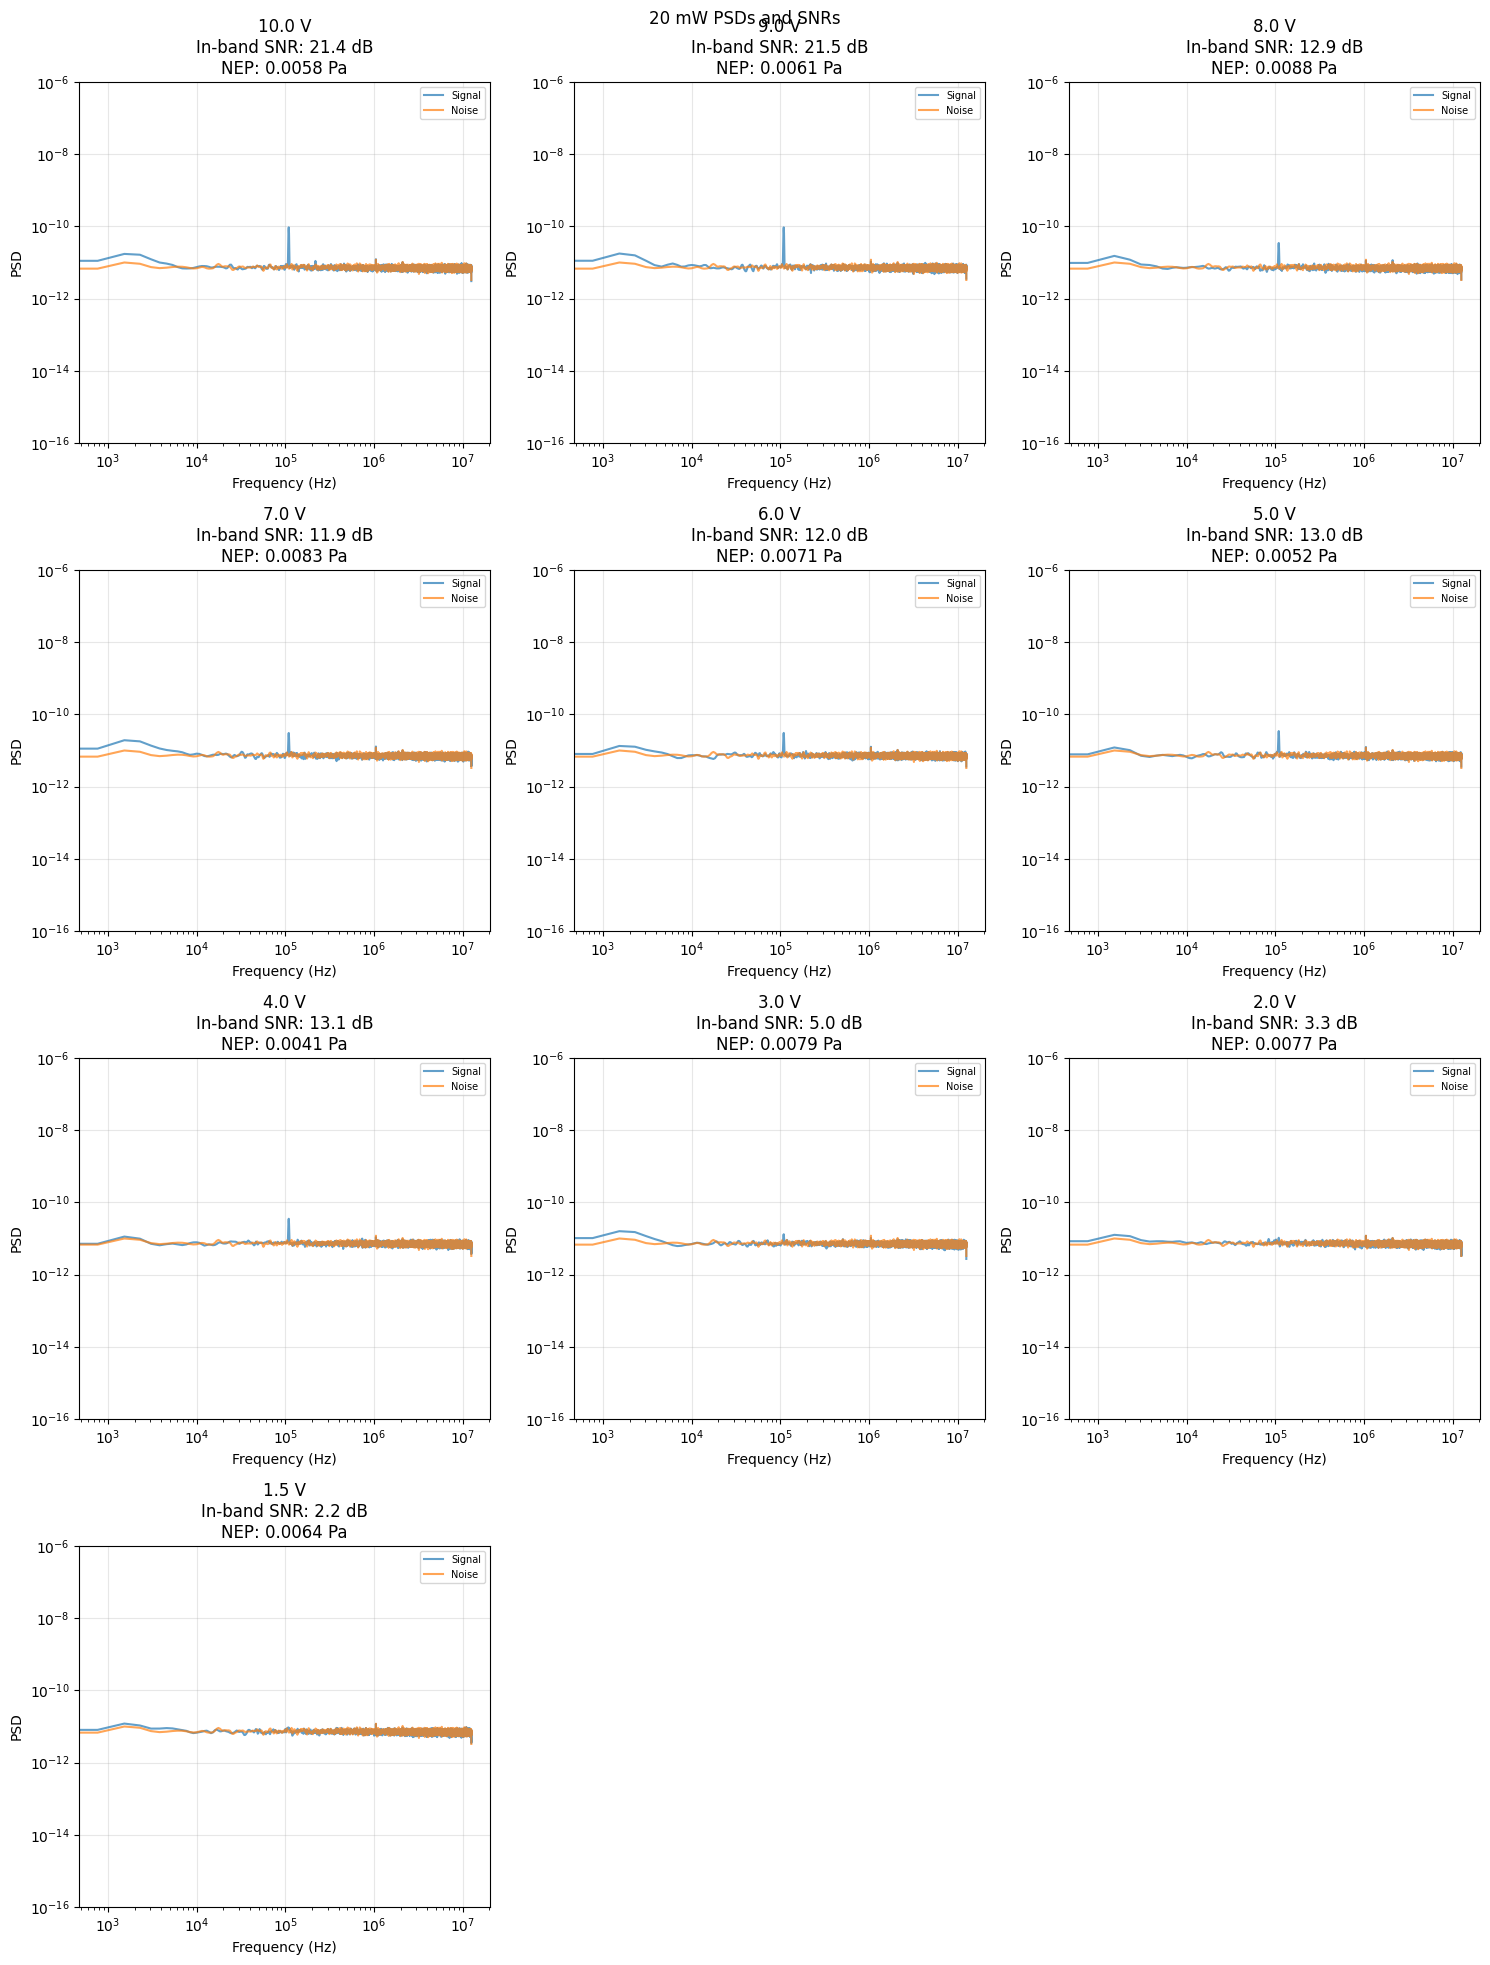

In [39]:
results = analysis_welches(20, "no", base_path, band_half_width_hz=1e3)

Analyzing 20mW_noMask: found 10 voltage scans
  Processing 20mW_noMask_10V with 5 signal files and 5 noise files
    In-band SNR: 21.44 dB
    NEP: 0.0058 Pa
  Processing 20mW_noMask_9V with 5 signal files and 5 noise files
    In-band SNR: 21.47 dB
    NEP: 0.0061 Pa
  Processing 20mW_noMask_8V with 5 signal files and 5 noise files
    In-band SNR: 12.93 dB
    NEP: 0.0088 Pa
  Processing 20mW_noMask_7V with 5 signal files and 5 noise files
    In-band SNR: 11.94 dB
    NEP: 0.0083 Pa
  Processing 20mW_noMask_6V with 5 signal files and 5 noise files
    In-band SNR: 12.02 dB
    NEP: 0.0071 Pa
  Processing 20mW_noMask_5V with 5 signal files and 5 noise files
    In-band SNR: 12.98 dB
    NEP: 0.0052 Pa
  Processing 20mW_noMask_4V with 5 signal files and 5 noise files
    In-band SNR: 13.13 dB
    NEP: 0.0041 Pa
  Processing 20mW_noMask_3V with 5 signal files and 5 noise files
    In-band SNR: 5.03 dB
    NEP: 0.0079 Pa
  Processing 20mW_noMask_2V with 5 signal files and 5 noise files


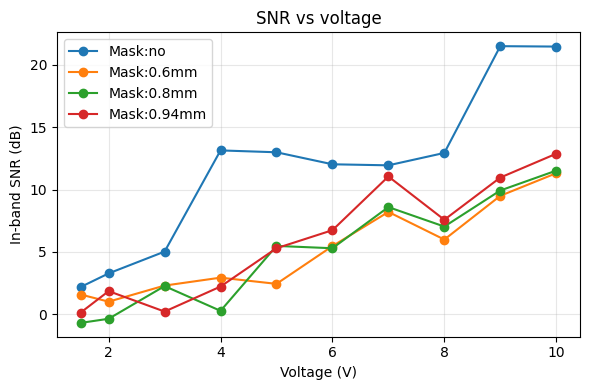

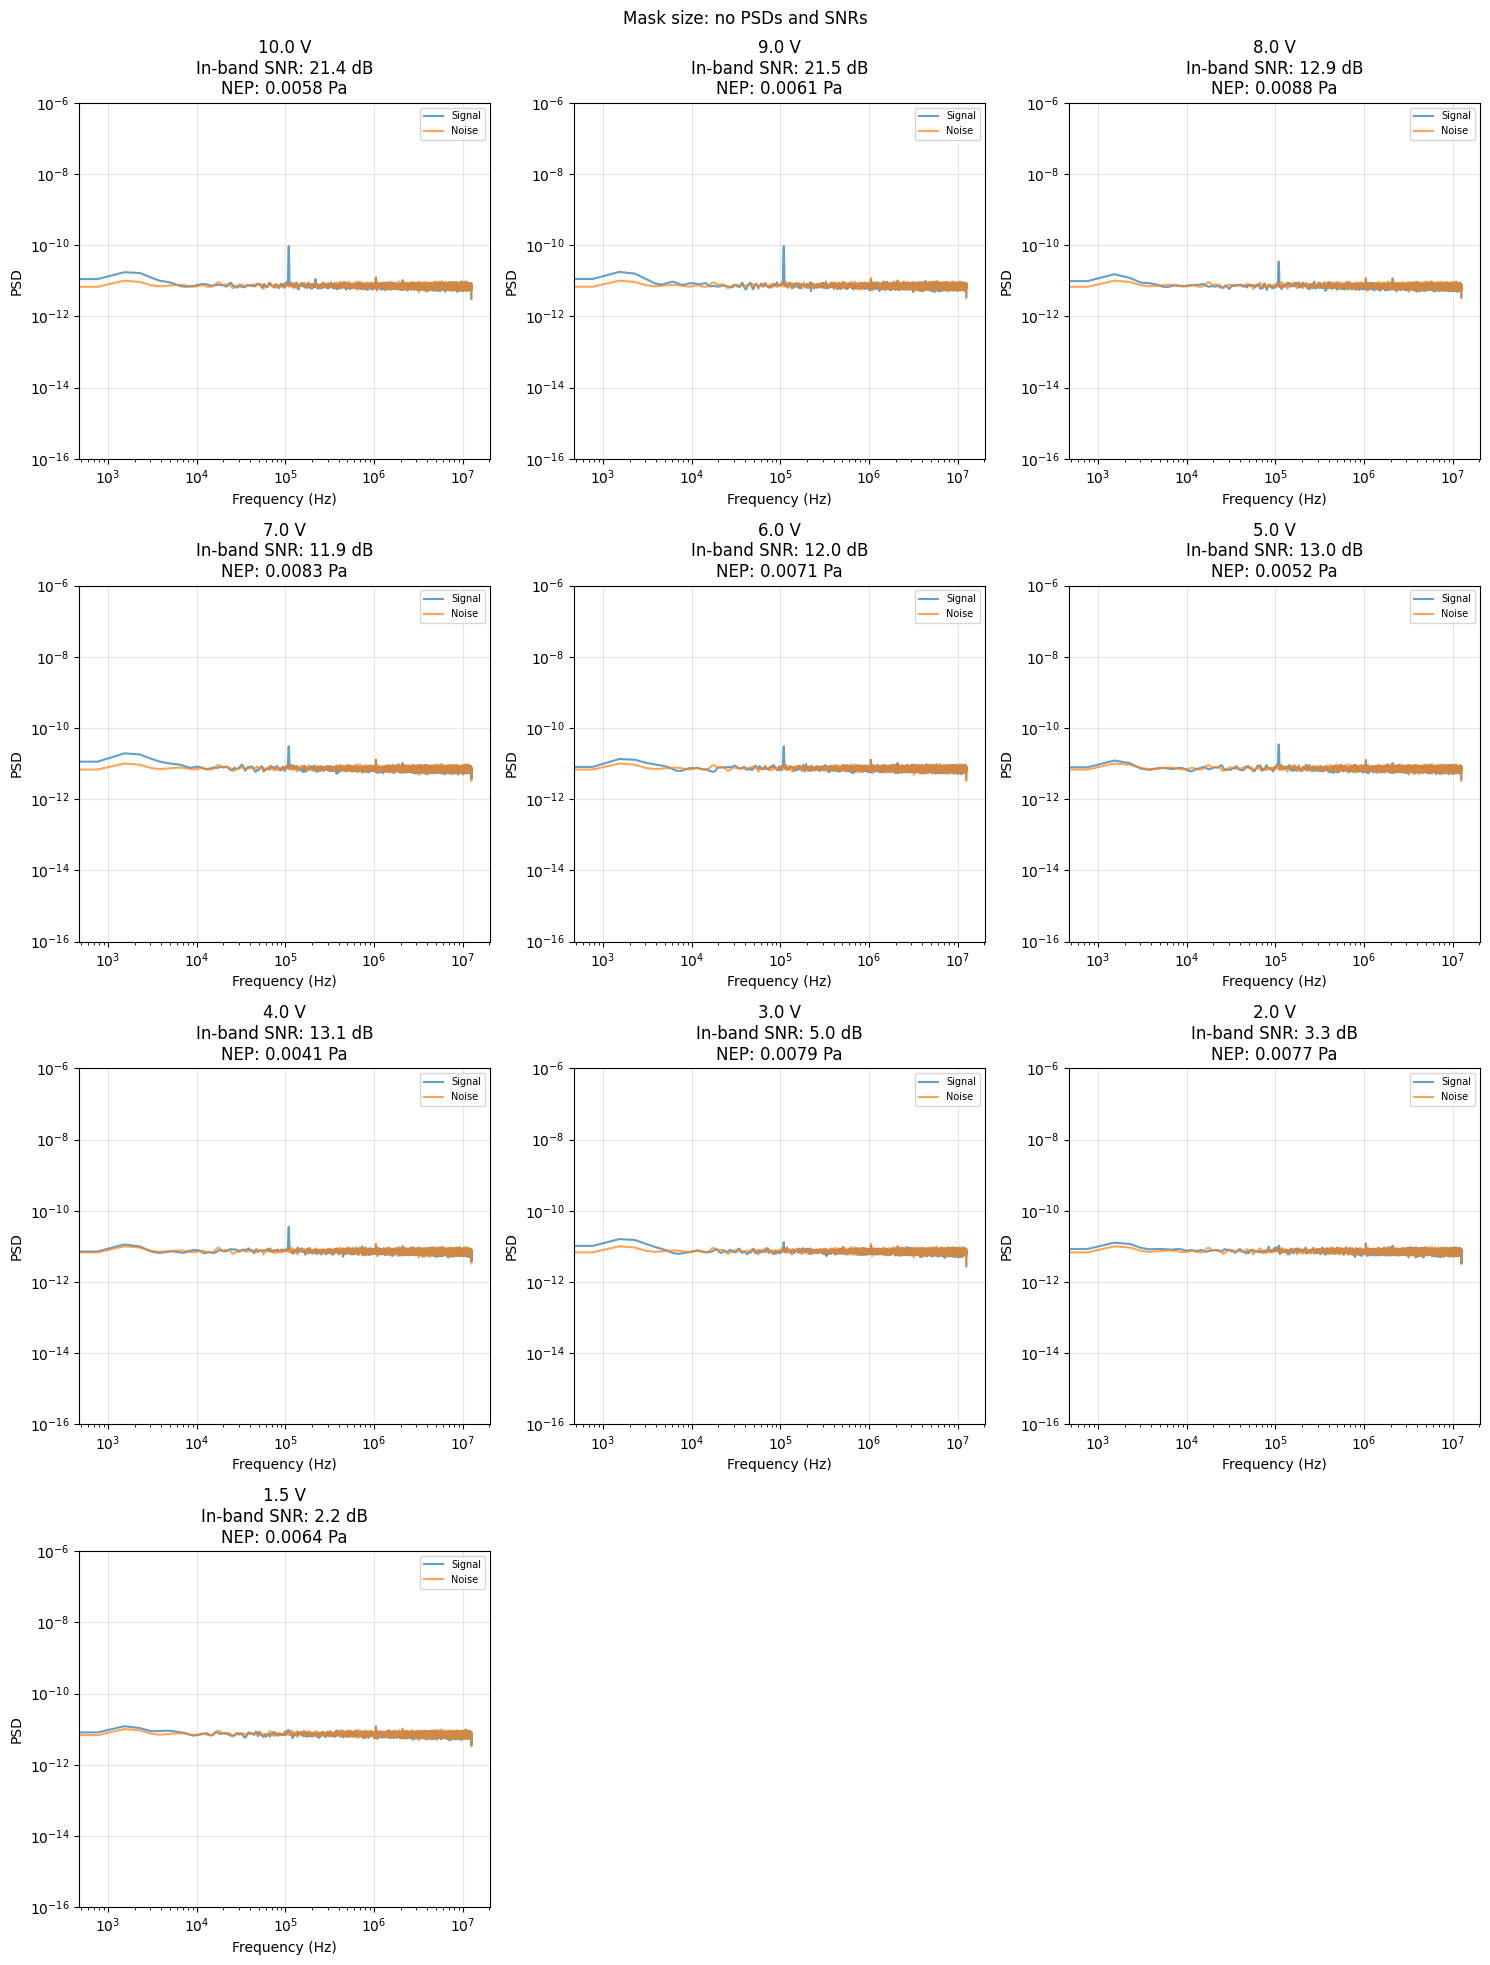

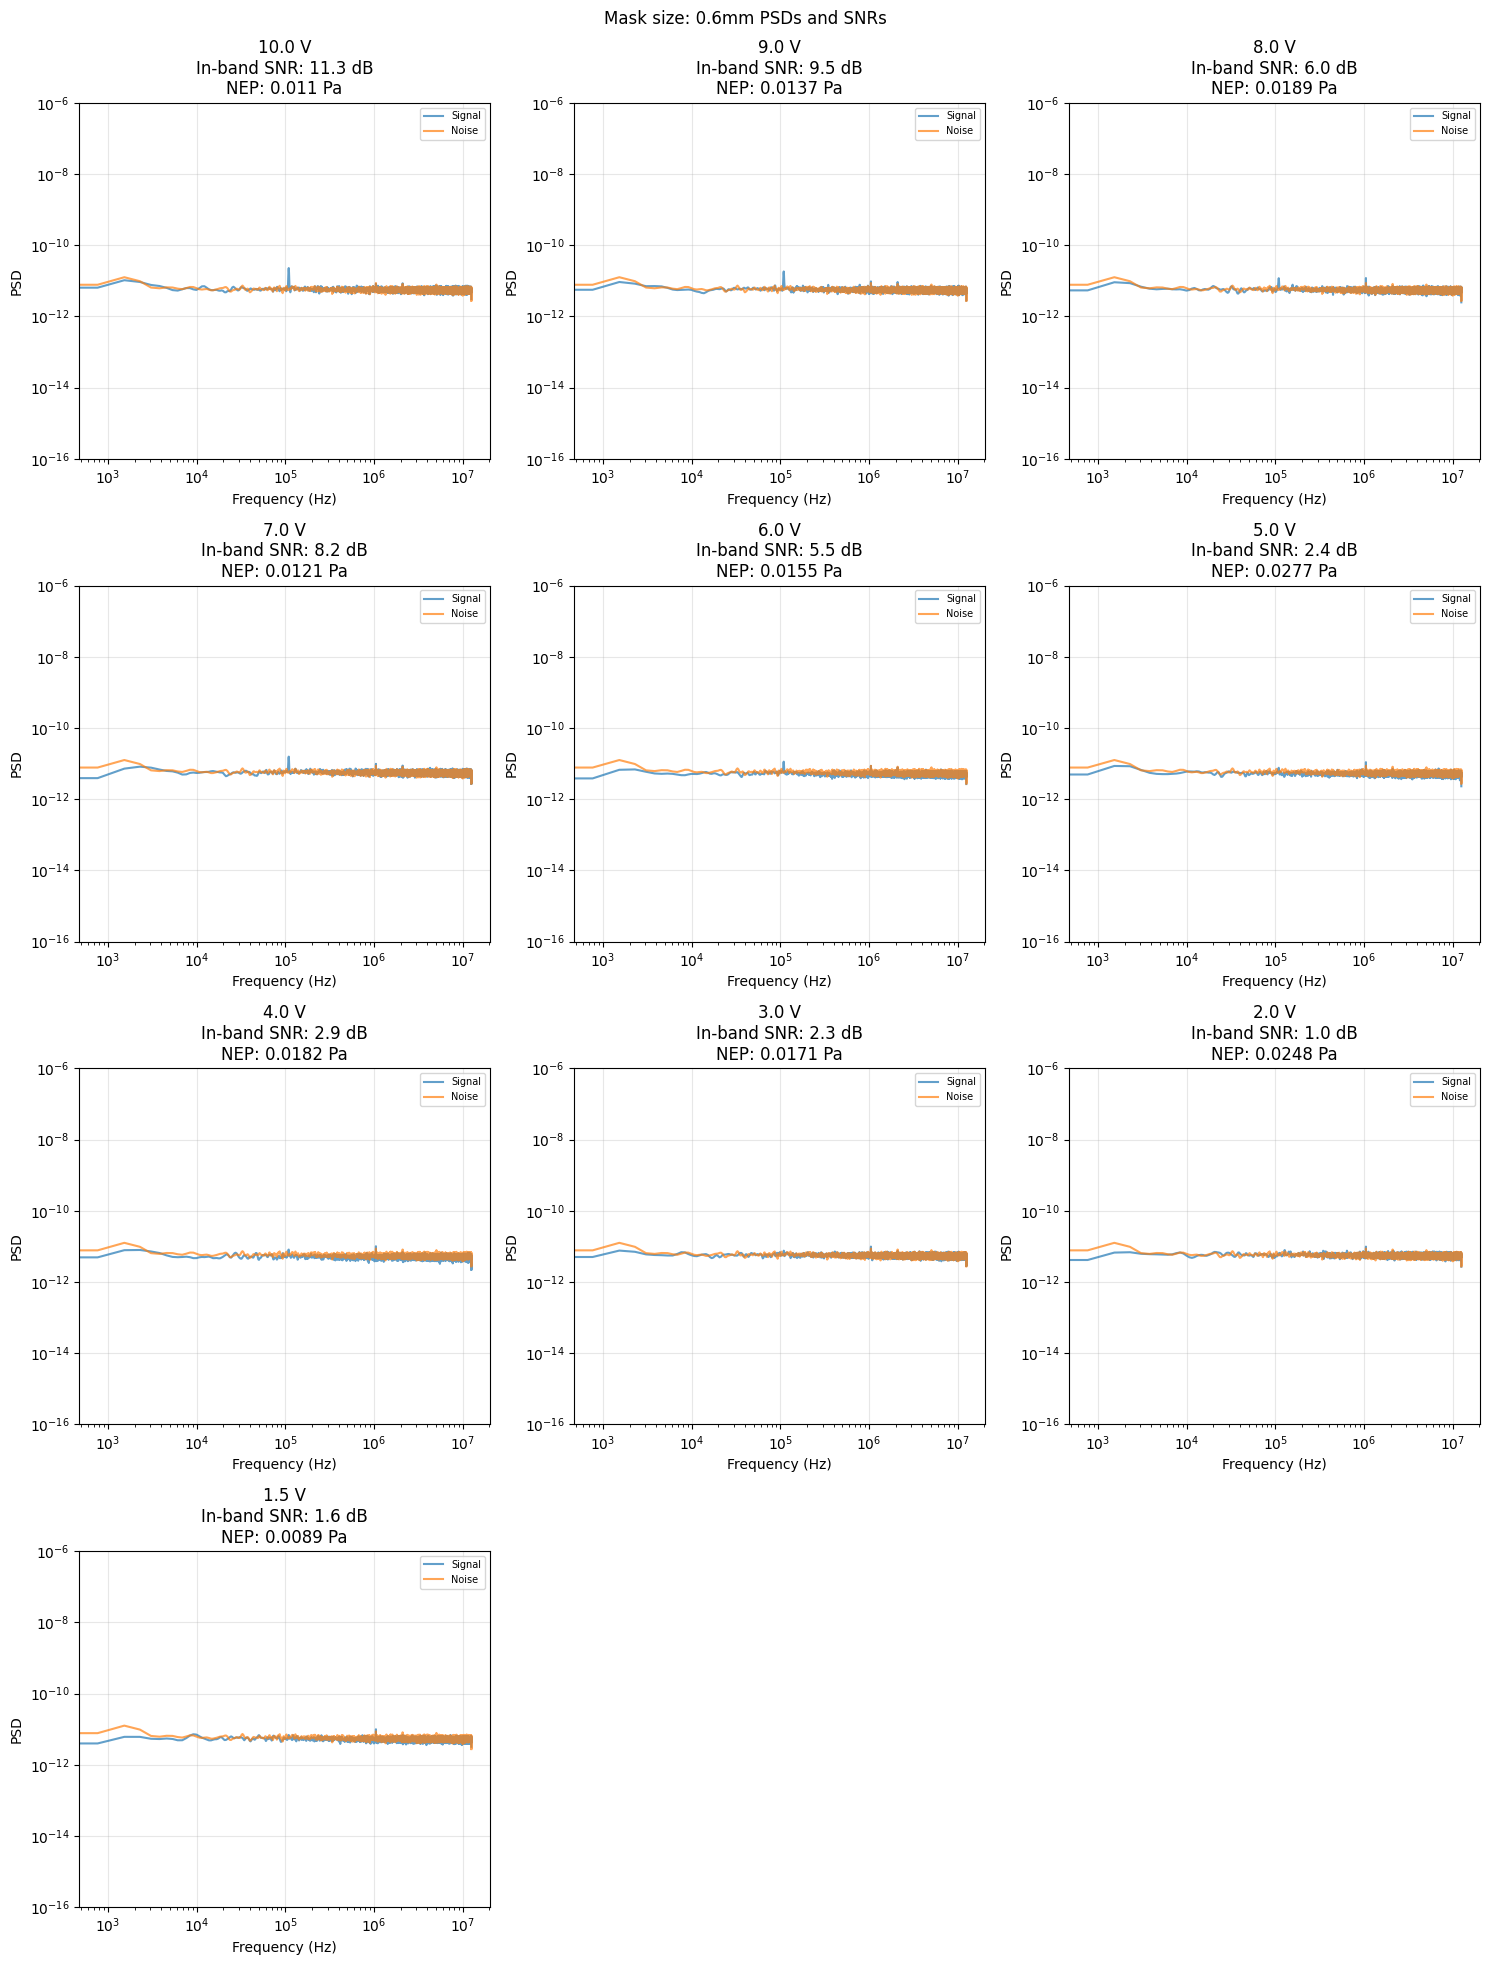

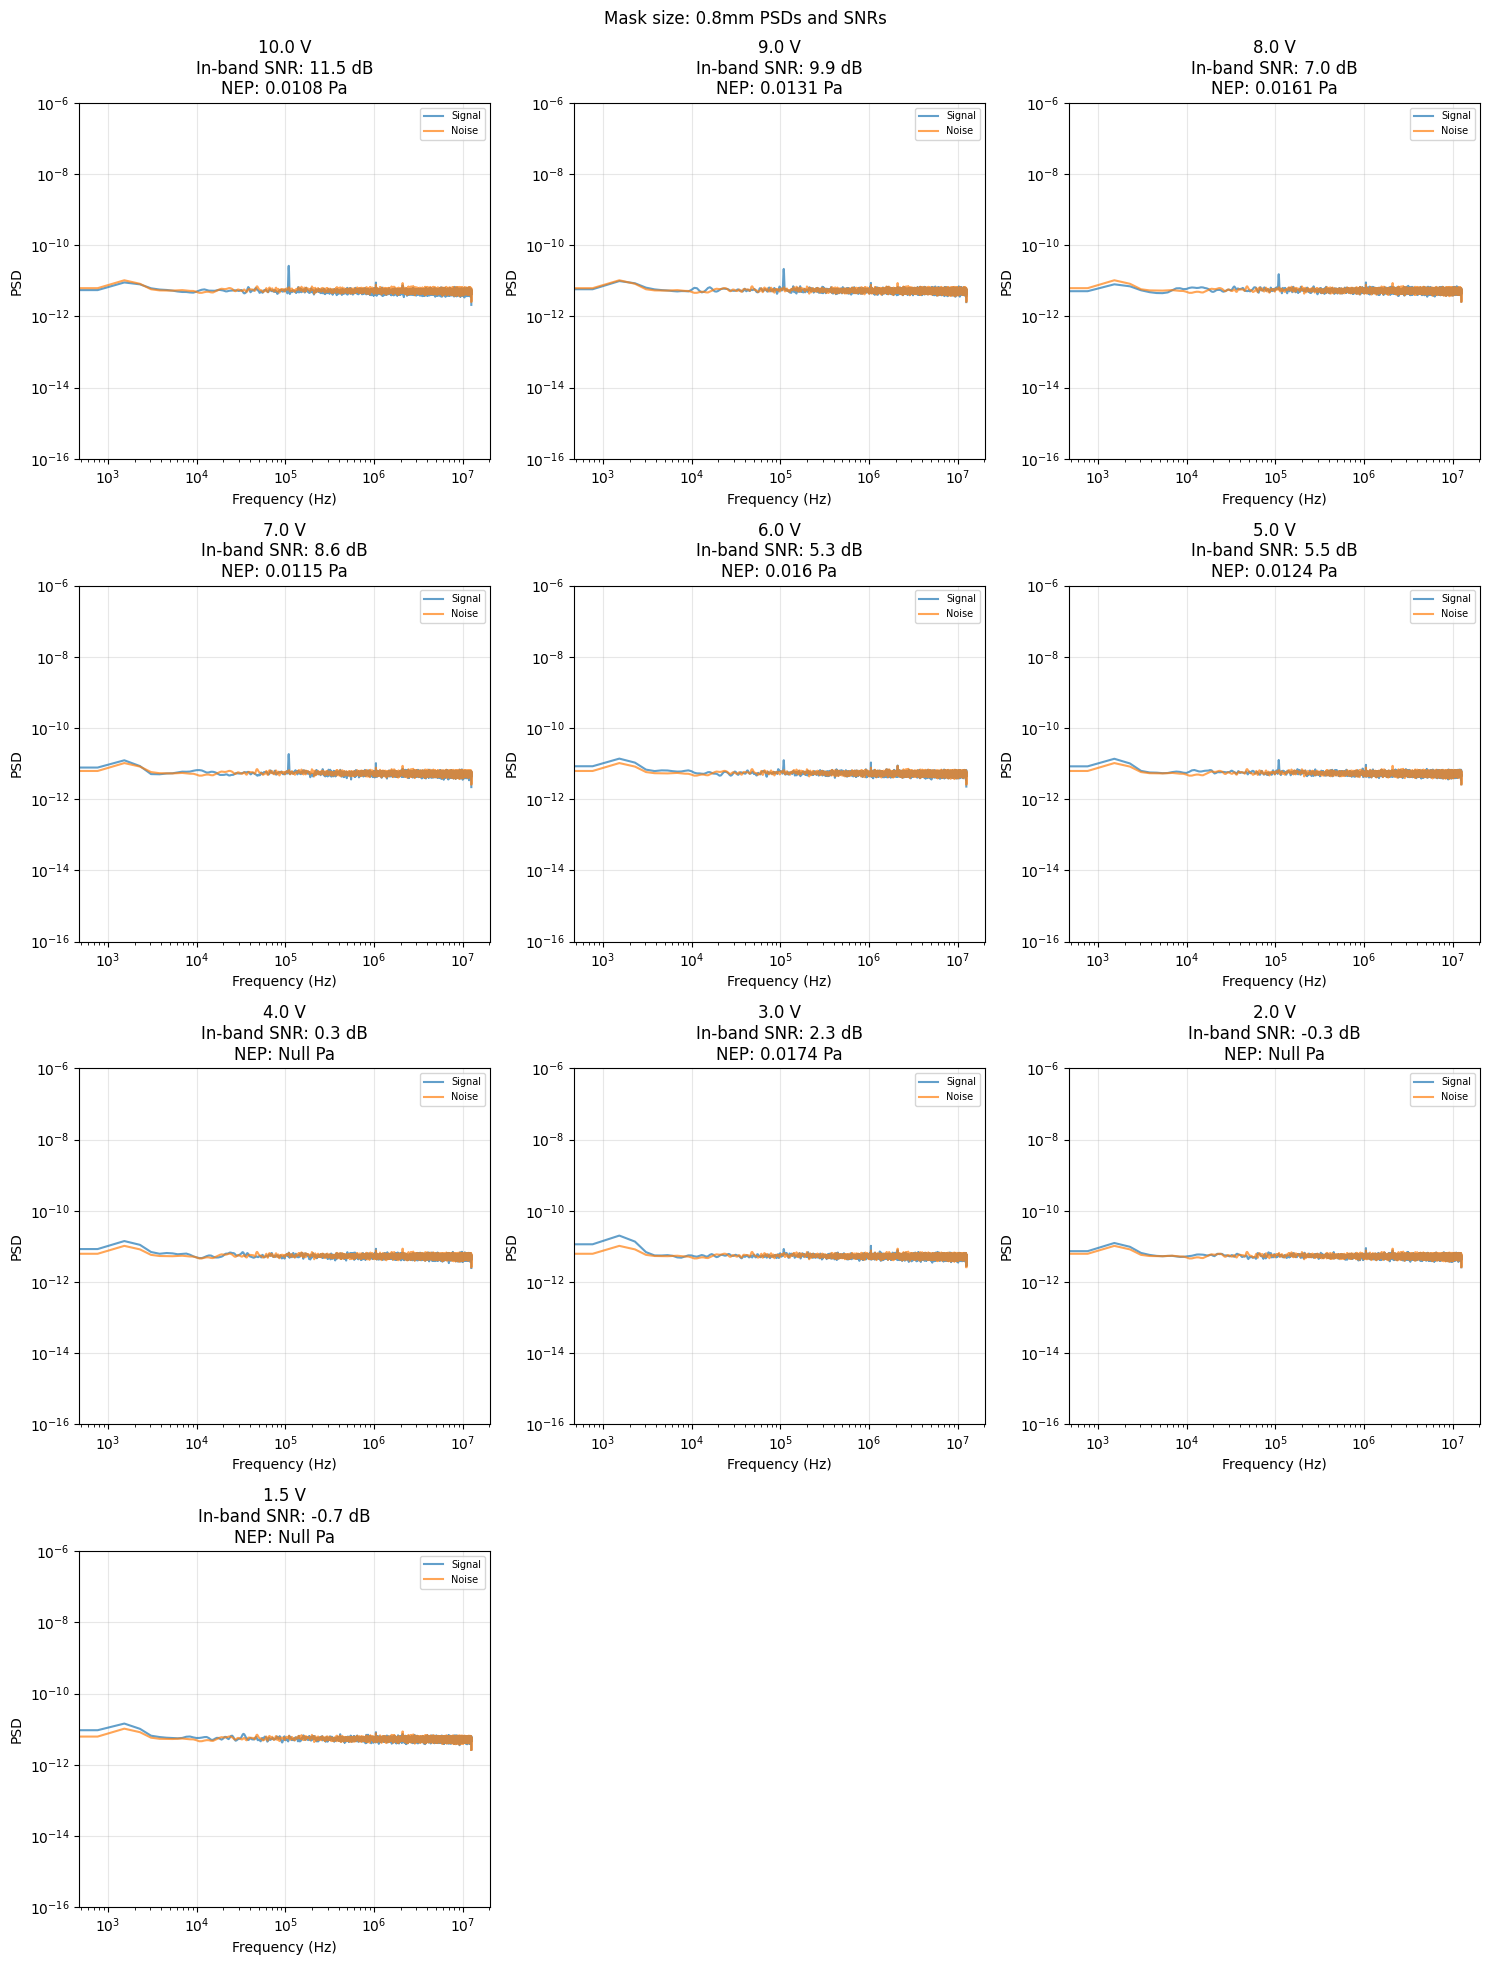

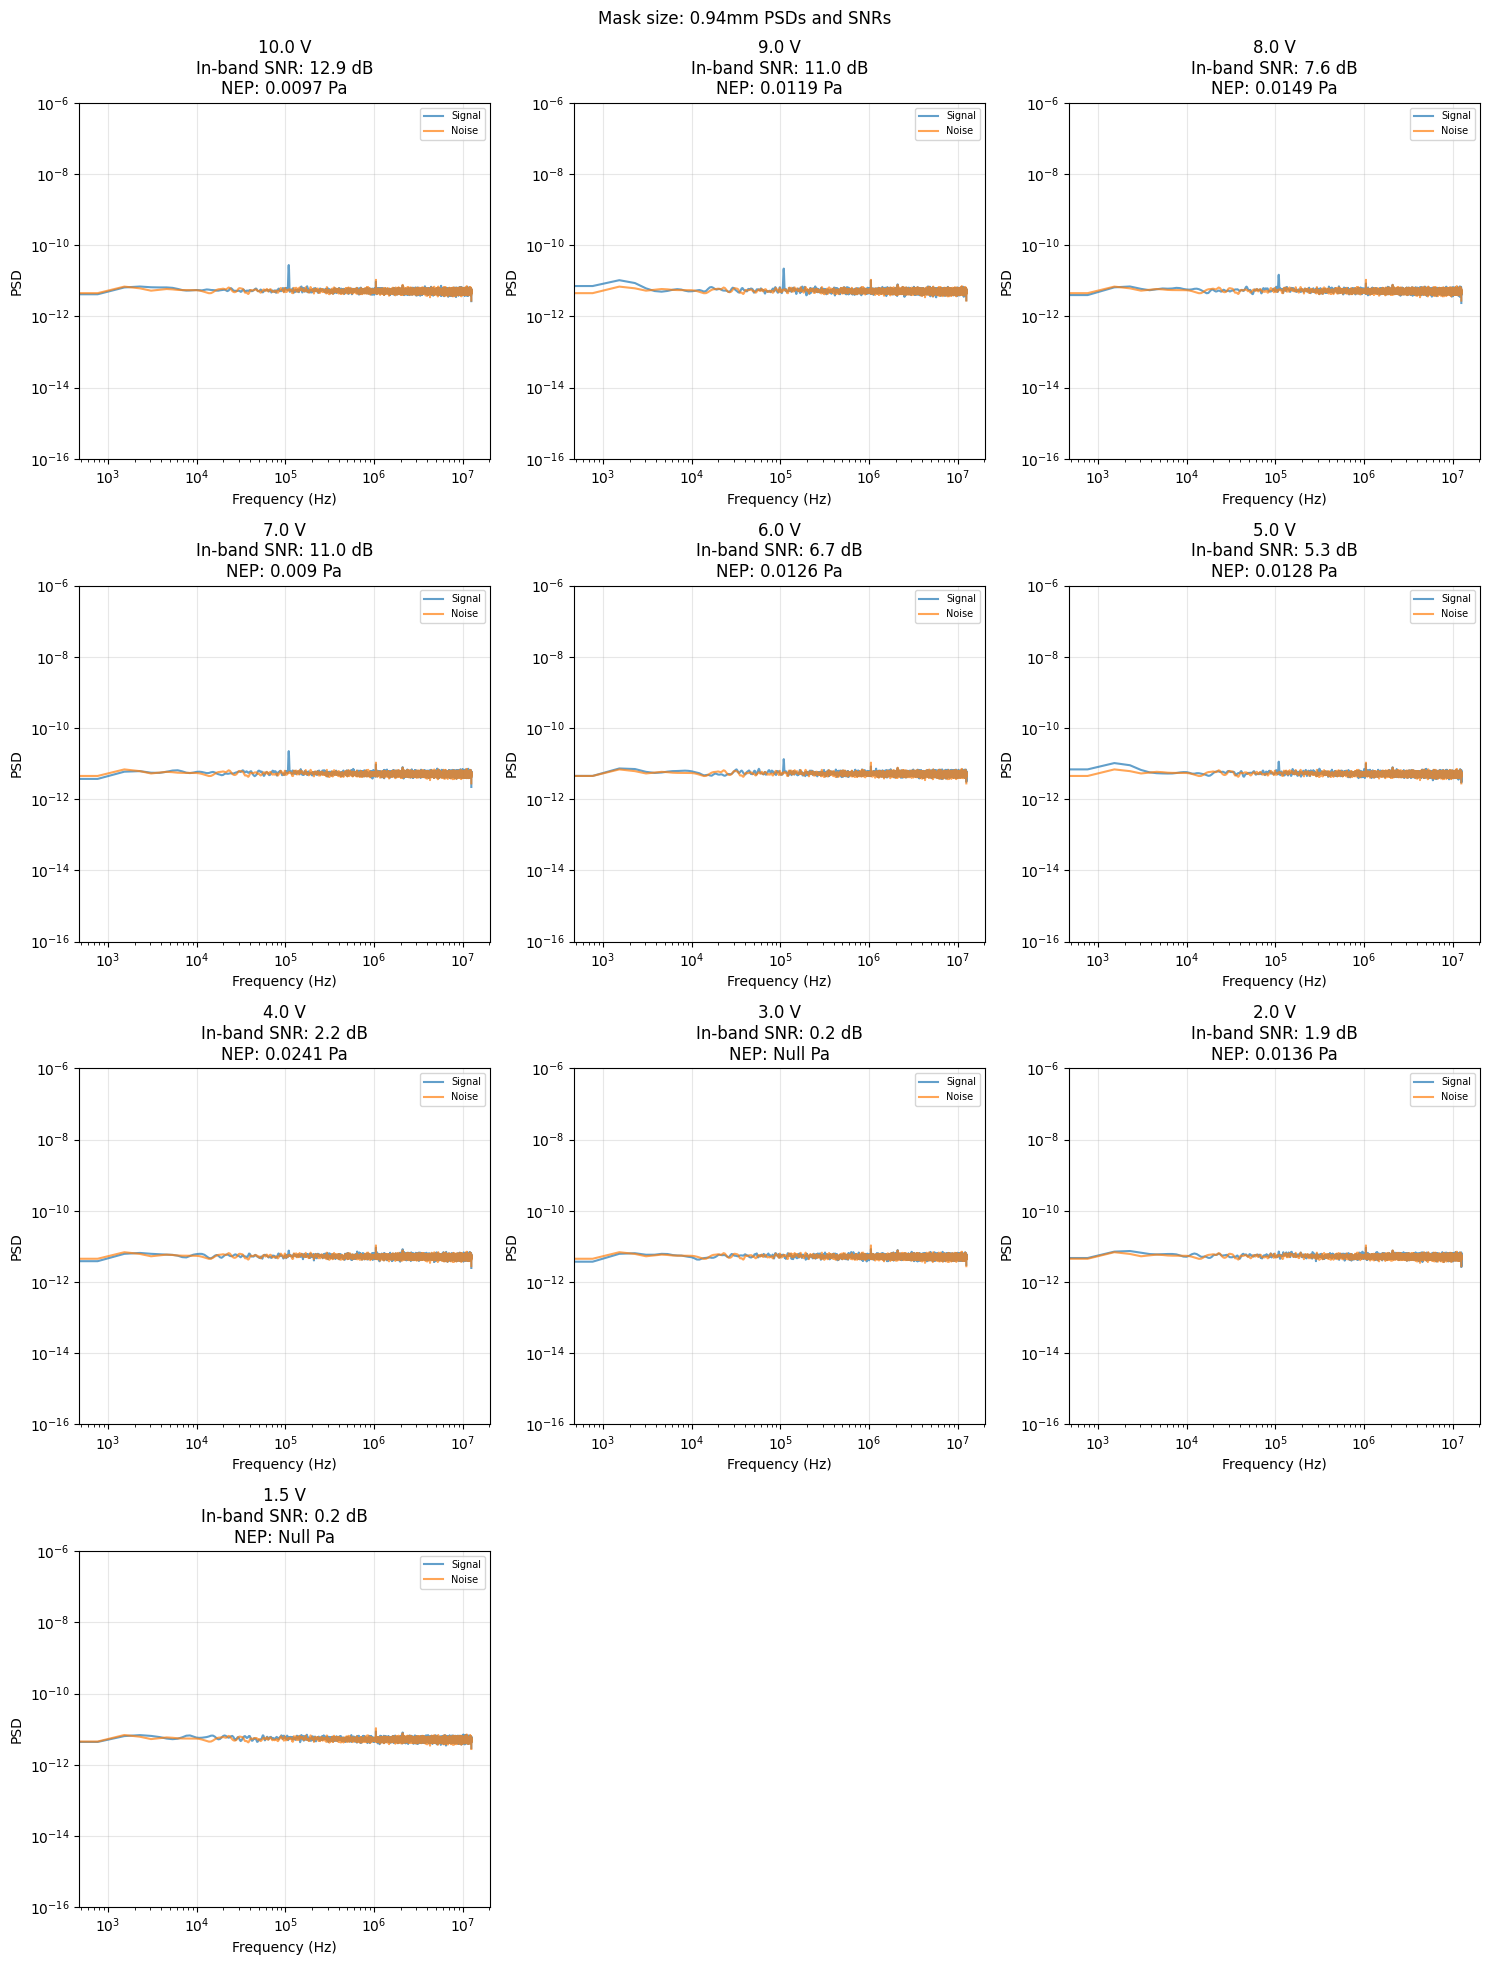

In [57]:
#the big kahoona

masks = ["no", "0.6mm", "0.8mm", "0.94mm"]
fig3, ax3 = plt.subplots(figsize=(6, 4))

for mask in masks:
    results = analysis_welches(20, mask, base_path)
    voltage_values = sorted(results.keys())
    snr_values = [results[voltage]["snr_inband"] for voltage in voltage_values]

    ax3.plot(voltage_values, snr_values, "o-", label=f"Mask:{mask}")

ax3.set_xlabel("Voltage (V)")
ax3.set_ylabel("In-band SNR (dB)")
ax3.set_title("SNR vs voltage")
ax3.grid(True, alpha=0.3)
ax3.legend()
fig3.tight_layout()
plt.show()